# Custom Russian Tokenizer: BPE-токенизатор для русского языка с нуля

**Задача:** обучить собственный токенизатор на русских текстах из корпуса `Helsinki-NLP/opus_books`,
сформировать словарь и сравнить, как он справляется с русской морфологией, по сравнению с готовыми токенизаторами RuBERT.

**Подход:** очистка русской части параллельного корпуса → обучение BPE-токенизатора библиотекой `tokenizers` →
пословное сравнение с `cointegrated/rubert-tiny2` и `DeepPavlov/rubert-base-cased` → метрики (токенов на слово, `[UNK]`) → эксперименты с размером словаря и объёмом корпуса.

**Содержание**
1. Подготовка корпуса
2. Обучение BPE-токенизатора
3. Сравнение с RuBERT и анализ морфологии
4. Метрики и эксперименты
5. Отчёт и выводы

**Запуск:** Google Colab (`Runtime → Run all`, GPU не нужен) или локально через Docker (`docker compose up -d`, см. README).

## 0. Подготовка окружения

Обучение токенизатора — это подсчёт частот пар символов, а не обучение нейросети, поэтому PyTorch и GPU не нужны.
В Colab библиотеки `datasets`, `tokenizers` и `transformers` обычно уже установлены, команда ниже доставит их, если чего-то не хватает.
В Docker-образе всё ставится из `requirements.txt`.

In [1]:
import sys

IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    !pip install -q datasets tokenizers transformers

Фиксируем `seed`: случайные примеры и отложенная выборка предложений будут одинаковыми при каждом запуске.

In [2]:
import json
import random
import re
import time
import unicodedata
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from datasets import load_dataset
from IPython.display import Markdown, display
from tokenizers import Tokenizer, decoders, models, normalizers, pre_tokenizers, processors, trainers
from transformers import AutoTokenizer

RANDOM_STATE = 42

random.seed(RANDOM_STATE)

pd.set_option('display.max_colwidth', 120)

[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


## 1. Подготовка корпуса

### 1.1 Загрузка датасета

[`Helsinki-NLP/opus_books`](https://huggingface.co/datasets/Helsinki-NLP/opus_books) — параллельный корпус переводов книг:
каждая строка содержит одно и то же предложение на двух языках. Языковая пара выбирается конфигом, берём `en-ru`.

Датасет скачивается с Hugging Face Hub при первом запуске и кэшируется на диске (в Docker — в папке `data/`).

Красное предупреждение `You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN...` можно игнорировать:
это не ошибка, а сообщение сервера Hugging Face о том, что загрузка идёт без аккаунта. Датасет и токенизаторы в этой работе публичные,
токен для них не нужен.

In [3]:
DATASET_NAME = 'Helsinki-NLP/opus_books'
DATASET_CONFIG = 'en-ru'

ds = load_dataset(DATASET_NAME, DATASET_CONFIG, split='train')
ds

Dataset({
    features: ['id', 'translation'],
    num_rows: 17496
})

In [4]:
print(ds.features)
ds[0]

{'id': Value('string'), 'translation': Translation(languages=['en', 'ru'])}


{'id': '0', 'translation': {'en': 'Anna Karenina', 'ru': 'Анна Каренина'}}

Каждая строка — словарь `translation` с ключами `en` и `ru`. Английская сторона для русского токенизатора не нужна,
оставляем только тексты по ключу `ru`.

In [5]:
ru_texts = [pair['ru'] for pair in ds['translation']]

print(f'Русских предложений: {len(ru_texts):,}')
print()
for text in random.Random(RANDOM_STATE).sample(ru_texts, 10):
    print('•', text)

Русских предложений: 17,496

• Левин, ставивший между тем ружье в шкаф, уже выходил из двери, но, услыхав слова купца, остановился.
• Степан Аркадьич улыбнулся.
• -- Постойте, княгиня, надевать перчатку, дайте поцеловать вашу ручку.
• Кити смотрела на дверь, сбираясь с силами, чтобы не покраснеть при входе Константина Левина.
• Левин слушал и придумывал и не мог придумать, что сказать.
• Придет или нет?
• -- Как успеем, Константин Дмитрич, -- сказал приказчик.
• -- Скверная история, но уморительная.
• Он спросил тихо, в то время как вблизи говорили, так что он надеялся, что его вопрос не услышат.
• Вы так хвалите всегда мужиков.


### 1.2 Первичный осмотр корпуса

Смотрим объём корпуса, длины предложений, словарный состав и набор символов.
Всё это напрямую влияет на токенизатор: он сможет выучить только те кусочки слов и те символы, которые встретятся в корпусе.

In [6]:
lengths = pd.Series([len(text) for text in ru_texts])
word_counts = Counter(
    word.lower()
    for text in ru_texts
    for word in re.findall(r'[а-яё]+', text, flags=re.IGNORECASE)
)

print(f'Символов всего:             {lengths.sum():,}')
print(f'Русских слов всего:         {sum(word_counts.values()):,}')
print(f'Разных словоформ:           {len(word_counts):,}')
print(f'Из них встречаются 1 раз:   {sum(1 for n in word_counts.values() if n == 1):,}')
print(f'Пустых строк:               {sum(1 for text in ru_texts if not text.strip())}')
print(f'Повторяющихся предложений:  {len(ru_texts) - len(set(ru_texts))}')
print()
print('Длина предложения, символов:')
lengths.describe().round(1)

Символов всего:             1,693,985
Русских слов всего:         269,984
Разных словоформ:           32,809
Из них встречаются 1 раз:   18,402
Пустых строк:               0
Повторяющихся предложений:  318

Длина предложения, символов:


count    17496.0
mean        96.8
std         80.4
min          1.0
25%         39.0
50%         76.0
75%        132.0
max       1093.0
dtype: float64

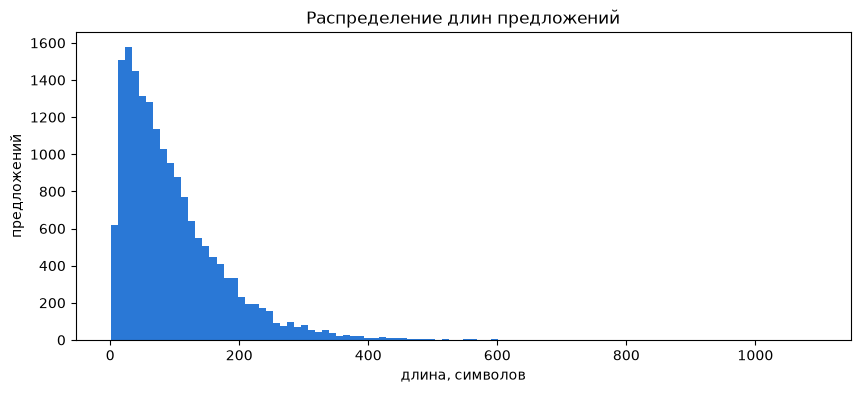

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(lengths, bins=100, color='#2a78d6')
ax.set_title('Распределение длин предложений')
ax.set_xlabel('длина, символов')
ax.set_ylabel('предложений')
plt.show()

Самые частые словоформы. В маленьком корпусе из одной книги среди них будут имена героев.

In [8]:
print(', '.join(f'{word} ({count})' for word, count in word_counts.most_common(40)))

и (12913), не (6535), что (6139), в (5721), он (5549), на (3592), она (3433), с (3358), я (3217), как (2685), но (2580), его (2579), это (2231), то (2040), к (1984), ее (1804), все (1792), было (1656), так (1424), сказал (1412), а (1397), же (1324), ему (1253), о (1243), за (1204), левин (1134), только (1016), ты (992), по (942), у (914), был (900), когда (863), из (836), для (827), сказала (827), бы (822), да (819), от (813), теперь (812), вы (758)


Самые короткие строки — на них хорошо видны артефакты форматирования.

In [9]:
short_lines = sorted({text for text in ru_texts if len(text) <= 4})
print(f'Разных строк длиной до 4 символов: {len(short_lines)}')
print(short_lines)

Разных строк длиной до 4 символов: 42
['I', 'II', 'III', 'IV', 'IX', 'V', 'VI', 'VII', 'VIII', 'X', 'XI', 'XII', 'XIII', 'XIV', 'XIX', 'XV', 'XVI', 'XVII', 'XX', 'XXI', 'XXII', 'XXIV', 'XXIX', 'XXV', 'XXVI', 'XXX', 'XXXI', 'XXXV', 'А?', 'Бац!', 'Во!', 'Где?', 'Да!', 'Да.', 'Да?', 'Жив!', 'Иди.', 'Как?', 'Мха!', 'Нет.', 'Ну?', 'Я...']


**Набор символов.** Символ, которого нет в корпусе, токенизатор не сможет выучить и заменит на `[UNK]`.
Проверяем, какие символы кроме русских букв встречаются, и есть ли в корпусе символы, обычные для современных текстов.

In [10]:
char_counts = Counter(char for text in ru_texts for char in text)
other_chars = {
    char: count
    for char, count in char_counts.items()
    if not re.fullmatch(r'[а-яёА-ЯЁ ]', char)
}

print(f'Разных символов в корпусе: {len(char_counts)}')
print()
print('Кроме русских букв и пробела:')
print(', '.join(f'{char!r} ({count})' for char, count in Counter(other_chars).most_common()))

Разных символов в корпусе: 134

Кроме русских букв и пробела:
',' (39345), '-' (23550), '.' (19395), '?' (2331), '"' (1551), '!' (1544), ';' (1108), 'e' (715), ':' (706), 'a' (462), 'n' (362), 'I' (354), 's' (333), 'i' (304), 'X' (302), 'l' (267), 'r' (264), 't' (259), 'o' (241), 'm' (227), 'u' (218), ')' (158), 'd' (157), 'c' (153), '(' (151), 'V' (120), 'p' (114), "'" (79), 'h' (74), 'f' (60), 'b' (55), 'g' (47), 'v' (41), 'L' (40), 'M' (32), 'z' (28), 'j' (19), 'x' (18), 'y' (17), 'C' (17), 'q' (17), 'A' (16), 'P' (13), 'w' (10), 'D' (9), 'E' (9), '1' (8), 'k' (8), 'J' (7), 'B' (6), '8' (6), 'T' (5), 'N' (5), 'K' (5), '6' (5), 'Q' (5), 'O' (5), 'H' (4), 'U' (4), '2' (4), '3' (4), 'S' (3), '0' (3), 'R' (2), '7' (2), '5' (2), '9' (2), 'Z' (2), 'W' (2), '4' (1), 'F' (1), 'Y' (1)


In [11]:
modern_chars = ['ё', 'Ё', '—', '–', '«', '»', '…', '№', '%', '€']

pd.DataFrame({
    'символ': modern_chars,
    'раз в корпусе': [char_counts.get(char, 0) for char in modern_chars],
}).set_index('символ').T

символ,ё,Ё,—,–,«,»,…,№,%,€
раз в корпусе,0,0,0,0,0,0,0,0,0,0


**Что показал осмотр:**

- **Корпус маленький.** 17 496 предложений, 1.69 млн символов, ~270 тыс. слов. Из 32 809 разных словоформ 18 402 (56%) встречаются
  всего один раз: токенизатор не сможет выучить их целиком и будет собирать из кусочков. Для сравнения, токенизаторы RuBERT обучались
  на гигабайтах текстов.
- **По сути это одна книга, «Анна Каренина».** Среди 30 самых частых словоформ есть `левин`. Лексика — проза XIX века,
  современных слов вроде «загуглить» здесь нет и быть не может.
- **Артефакты форматирования:**
  - прямая речь оформлена двойным дефисом `--` вместо тире (поэтому `-` — второй по частоте символ после запятой);
  - заголовки глав римскими цифрами (`I`, `XIV`, `XXXV`) идут отдельными строками;
  - встречаются многоточия из 4–5 точек.
- **Латиница** — это французские и английские вставки в тексте Толстого. Это настоящий текст, а не мусор, поэтому её оставляем.
- **Пустых строк нет**, а 318 повторов — короткие реплики вроде «Да.» или «Ну?». Это нормальный текст, не ошибка.
- **Нет символов современного текста:** `ё` (в книге везде «е»: `ее` встречается 1 804 раза), тире `—`, кавычки `«»`, `…`, `№`, `%`, `€`,
  а цифр всего несколько десятков. Если ничего не сделать, токенизатор вернёт на них `[UNK]`. Это учтём при очистке и настройке токенизатора.

### 1.3 Очистка текста

Токенизатор выучит всё, что часто встречается в корпусе, в том числе мусор. Если оставить `--` или `XIV`,
в словаре появятся бесполезные токены, которые займут место полезных кусочков слов.

| Что делаем | Пример | Зачем |
|---|---|---|
| Unicode-нормализация NFC | `й` из двух кодов → один код | одна и та же буква не должна превращаться в два разных символа |
| `--` → `—` | `-- Да? -- спросил он` → `— Да? — спросил он` | артефакт перевода книги в простой текст; тире в прямой речи и дефис в словах (`кто-то`) должны быть разными символами |
| 3 и более точек → `...` | `Люби кататься.....` → `Люби кататься...` | иначе в словарь попадут `....` и `.....` как отдельные токены |
| схлопнуть пробелы, обрезать края | | косметика |
| удалить строки-заголовки глав | `XIV` | это не текст, а нумерация глав |
| удалить пустые строки | | после очистки строка может оказаться пустой |

**Чего не делаем, в отличие от классической предобработки текста для классификаторов:** не удаляем пунктуацию, не приводим к нижнему регистру,
не лемматизируем. Токенизатор должен работать с настоящим текстом: запятые, заглавные буквы и все формы слов —
ровно то, что потом придёт на вход модели. Лемматизация лишила бы нас главного: увидеть, выучит ли токенизатор окончания.

Латиницу (французские вставки) и повторы коротких реплик оставляем — это настоящий текст.

Сначала посчитаем, сколько строк содержат каждый артефакт.

In [12]:
ROMAN_HEADING = re.compile(r'[IVXLC]+\.?')

artifacts = {
    'двойной дефис --': lambda text: '--' in text,
    'заголовок главы (XIV)': lambda text: ROMAN_HEADING.fullmatch(text.strip()) is not None,
    'многоточие из 4+ точек': lambda text: re.search(r'\.{4,}', text) is not None,
    'двойные пробелы, пробелы по краям': lambda text: re.search(r'\s{2,}', text) is not None or text != text.strip(),
    'не в форме NFC': lambda text: not unicodedata.is_normalized('NFC', text),
}

pd.DataFrame(
    {'строк': {name: sum(1 for text in ru_texts if check(text)) for name, check in artifacts.items()}}
)

,строк
двойной дефис --,6209
заголовок главы (XIV),239
многоточие из 4+ точек,14
"двойные пробелы, пробелы по краям",0
не в форме NFC,0


Функция очистки одного предложения и проверка, нужно ли его выбросить.

In [13]:
def clean_text(text: str) -> str:
    text = unicodedata.normalize('NFC', text)
    text = re.sub(r'-{2,}', '—', text)
    text = re.sub(r'\.{3,}', '...', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()


def is_garbage(text: str) -> bool:
    return not text or ROMAN_HEADING.fullmatch(text) is not None


clean_texts = []
for text in ru_texts:
    cleaned = clean_text(text)
    if not is_garbage(cleaned):
        clean_texts.append(cleaned)

print(f'Было предложений:   {len(ru_texts):,}')
print(f'Удалено:            {len(ru_texts) - len(clean_texts):,}')
print(f'Осталось:           {len(clean_texts):,}')
print(f'Символов осталось:  {sum(len(text) for text in clean_texts):,}')

Было предложений:   17,496
Удалено:            239
Осталось:           17,257
Символов осталось:  1,682,232


Проверка «было → стало» на строках, которые очистка изменила.

In [14]:
changed = [(text, clean_text(text)) for text in ru_texts if clean_text(text) != text]

print(f'Изменено строк: {len(changed):,}')
pd.DataFrame(
    random.Random(RANDOM_STATE).sample(changed, 8),
    columns=['было', 'стало'],
)

Изменено строк: 6,216


,было,стало
0,"-- Да, я в тот же день уехал.","— Да, я в тот же день уехал."
1,"Дело сестричек (это было филантропическое, религиозно-патриотическое учреждение) пошло было прекрасно, но с этими го...","Дело сестричек (это было филантропическое, религиозно-патриотическое учреждение) пошло было прекрасно, но с этими го..."
2,"-- Здесь, в Москве?","— Здесь, в Москве?"
3,"""Разве я не знаю, что это -- бесконечное пространство и что оно не круглый свод?","""Разве я не знаю, что это — бесконечное пространство и что оно не круглый свод?"
4,"Сережа пронзительно, как это часто бывало с ним, вскрикнул: ""А, мама!"" -- и остановился в нерешительности: идти ли к...","Сережа пронзительно, как это часто бывало с ним, вскрикнул: ""А, мама!"" — и остановился в нерешительности: идти ли к ..."
5,"""И у него там тоже какая-то своя философия есть на службу своих наклонностей"", -- подумал он.","""И у него там тоже какая-то своя философия есть на службу своих наклонностей"", — подумал он."
6,"-- Ну, так она второй ангел, -- сказал князь улыбаясь. -- Она называет ангелом нумер первый mademoiselle Вареньку.","— Ну, так она второй ангел, — сказал князь улыбаясь. — Она называет ангелом нумер первый mademoiselle Вареньку."
7,-- Я удивляюсь родителям.,— Я удивляюсь родителям.


Повторная проверка: после очистки артефактов не осталось.

In [15]:
pd.DataFrame(
    {'строк после очистки': {name: sum(1 for text in clean_texts if check(text)) for name, check in artifacts.items()}}
)

,строк после очистки
двойной дефис --,0
заголовок главы (XIV),0
многоточие из 4+ точек,0
"двойные пробелы, пробелы по краям",0
не в форме NFC,0


### 1.4 Отложенная выборка

Откладываем 5% предложений, которые токенизатор не увидит при обучении. На них в разделе 4 честно посчитаем,
насколько мелко он режет незнакомый, но похожий текст. Та же идея, что train/test в классическом ML:
проверять модель на том, на чём она училась, нечестно — результат будет завышен.

In [16]:
HOLDOUT_SHARE = 0.05

shuffled_texts = clean_texts.copy()
random.Random(RANDOM_STATE).shuffle(shuffled_texts)

holdout_size = int(len(shuffled_texts) * HOLDOUT_SHARE)
holdout_texts = shuffled_texts[:holdout_size]
train_texts = shuffled_texts[holdout_size:]

print(f'Предложений для обучения токенизатора: {len(train_texts):,}')
print(f'Предложений отложено для проверки:     {len(holdout_texts):,}')

Предложений для обучения токенизатора: 16,395
Предложений отложено для проверки:     862


### 1.5 Генератор батчей

`train_from_iterator` из библиотеки `tokenizers` принимает **итератор**: тексты приходят порциями (батчами), и весь корпус
не обязан лежать в памяти одним списком. Функция с `yield` — это **генератор**: при каждом обращении она отдаёт следующий батч
и «замирает» до следующего запроса, не создавая копию всех данных.

Наш корпус занимает всего несколько мегабайт, поэтому очищенные тексты держим в списке, а генератор нарезает его на батчи.
Для корпусов в десятки гигабайт тексты читали бы с диска потоком (`load_dataset(..., streaming=True)`) и чистили на лету,
но интерфейс для токенизатора остался бы тем же: генератор, отдающий списки строк.

In [17]:
BATCH_SIZE = 1000


def batch_iterator(texts: list[str], batch_size: int = BATCH_SIZE):
    for start in range(0, len(texts), batch_size):
        yield texts[start:start + batch_size]


batches = batch_iterator(train_texts)
first_batch = next(batches)

print(f'Тип объекта: {type(batches).__name__}')
print(f'Предложений в первом батче: {len(first_batch)}')
print(f'Всего батчей: {sum(1 for _ in batch_iterator(train_texts))}')
print()
for text in first_batch[:3]:
    print('•', text)

Тип объекта: generator
Предложений в первом батче: 1000
Всего батчей: 17

• Посмотревшись в зеркало, Левин заметил, что он красен; но он был уверен, что не пьян, и пошел по ковровой лестнице вверх за Степаном Аркадьичем.
• Был десятый час, когда он во второй раз пришел к крыльцу Щербацких.
• Тут вдруг заговорило несколько голосов, и высокий дворянин с перстнем, все более и более озлобляясь, кричал громче и громче. Но нельзя было разобрать, что он говорил.


## 2. Обучение BPE-токенизатора

Токенизатор в библиотеке `tokenizers` собирается из деталей, каждая отвечает за свой этап:

```
текст → Normalizer → Pre-tokenizer → Model (BPE) → Post-processor → токены и id
                                                        Decoder: id → текст
```

| Деталь | Что делает |
|---|---|
| **Normalizer** | приводит текст к единому виду (Unicode, замены символов) |
| **Pre-tokenizer** | грубо режет текст на «слова»: по пробелам, отделяет знаки препинания и цифры |
| **Model** | сам алгоритм: режет каждое «слово» на подслова по выученному словарю |
| **Post-processor** | добавляет служебные токены, например `[CLS] ... [SEP]` |
| **Decoder** | собирает текст обратно из токенов |

Собираем детали по очереди, затем обучаем модель на корпусе.

### 2.1 Алгоритм: BPE

**BPE (Byte Pair Encoding)** строит словарь снизу вверх:
1. начальный словарь — все отдельные символы корпуса;
2. находим самую частую пару соседних токенов (например, `с` + `т`) и склеиваем её в новый токен `ст`;
3. повторяем, пока словарь не дорастёт до заданного размера.

Результат обучения — словарь и упорядоченный список слияний (merges). Новый текст режется применением тех же слияний в том же порядке.
BPE лежит в основе токенизаторов GPT, LLaMA, Qwen.

`continuing_subword_prefix='##'` помечает кусочки из середины и конца слова: `пере` `##дум` `##ал`. Так же делают токенизаторы RuBERT,
с которыми будем сравнивать, — таблицы сравнения будут читаться одинаково.

Пока модель пустая: ни словаря, ни слияний.

In [18]:
empty_tokenizer = Tokenizer(models.BPE(unk_token='[UNK]', continuing_subword_prefix='##'))

print(f'Токенов в словаре до обучения: {empty_tokenizer.get_vocab_size()}')

Токенов в словаре до обучения: 0


### 2.2 Normalizer

- **NFC** — Unicode-нормализация: одна буква всегда записана одним и тем же кодом.
- **`ё` → `е`.** В корпусе нет ни одной буквы `ё` (в книге везде «е»), поэтому токенизатор не выучил бы ни одного кусочка с ней,
  и любое слово с `ё` получило бы `[UNK]`. Нормализатор применяется и при обучении, и при каждом использовании токенизатора,
  поэтому `ёжик` во входном тексте превратится в `ежик`.
- **Регистр сохраняем.** Готовые токенизаторы RuBERT тоже различают регистр, а имена собственные без заглавной буквы теряют информацию.

In [19]:
ru_normalizer = normalizers.Sequence([
    normalizers.NFC(),
    normalizers.Replace('ё', 'е'),
    normalizers.Replace('Ё', 'Е'),
])

ru_normalizer.normalize_str('Её ёжик съел ещё яблоко')

'Ее ежик съел еще яблоко'

### 2.3 Pre-tokenizer

BPE склеивает символы только внутри одного куска, который выдал pre-tokenizer. Поэтому:
- **`WhitespaceSplit`** режет по пробелам — токен никогда не захватит два слова;
- **`Punctuation('isolated')`** отделяет каждый знак препинания. Без этого в словарь попали бы `сказал,` и `сказал.` —
  одно слово «размножилось» бы по знакам препинания;
- **`Digits(individual_digits=True)`** режет числа на отдельные цифры, чтобы не учить токены для каждого числа.

In [20]:
ru_pre_tokenizer = pre_tokenizers.Sequence([
    pre_tokenizers.WhitespaceSplit(),
    pre_tokenizers.Punctuation(behavior='isolated'),
    pre_tokenizers.Digits(individual_digits=True),
])

ru_pre_tokenizer.pre_tokenize_str('— Да?! — спросил он, улыбаясь в 1873 году.')

[('—', (0, 1)),
 ('Да', (2, 4)),
 ('?', (4, 5)),
 ('!', (5, 6)),
 ('—', (7, 8)),
 ('спросил', (9, 16)),
 ('он', (17, 19)),
 (',', (19, 20)),
 ('улыбаясь', (21, 29)),
 ('в', (30, 31)),
 ('1', (32, 33)),
 ('8', (33, 34)),
 ('7', (34, 35)),
 ('3', (35, 36)),
 ('году', (37, 41)),
 ('.', (41, 42))]

Каждый кусок возвращается вместе с позициями начала и конца в исходной строке (offsets).
`?` и `!` стали отдельными кусками, `1873` — четырьмя цифрами.

### 2.4 Гиперпараметры обучения (Trainer)

- **`vocab_size = 16 000`** — размер словаря. Задание предлагает 10–30 тыс. Наш корпус маленький: при `min_frequency=2`
  на нём набирается только около 24.6 тыс. токенов, дальше склеивать нечего. 16 тыс. — с запасом ниже этого потолка
  (влияние размера словаря проверим в разделе 4).
- **`min_frequency = 2`** — не склеивать пару, если она встретилась всего один раз: такое слияние не обобщается, это зазубривание.
- **Специальные токены** получат id 0–4:
  - `[PAD]` — заполнитель для выравнивания текстов в батче по длине;
  - `[UNK]` — неизвестный символ;
  - `[CLS]` — начало текста (в BERT его вектор описывает весь текст);
  - `[SEP]` — конец текста или граница между двумя текстами;
  - `[MASK]` — «закрытое» слово, которое BERT учится угадывать.
- **`initial_alphabet`** — символы, которые обязательно попадут в словарь, даже если их не было в корпусе: тире, кавычки-«ёлочки»,
  `…`, `№`, `%`, `€` и цифры. Знаки препинания pre-tokenizer всегда отделяет от слов, поэтому им достаточно быть в словаре как
  отдельным токенам. Для букв так не получится: внутри слова нужен вариант с префиксом (`##ё`), которого `initial_alphabet` не создаёт.
  Поэтому `ё` решили нормализатором.

In [21]:
VOCAB_SIZE = 16_000
MIN_FREQUENCY = 2
SPECIAL_TOKENS = ['[PAD]', '[UNK]', '[CLS]', '[SEP]', '[MASK]']
EXTRA_ALPHABET = list('—–«»„“”…№%€') + list('0123456789')

### 2.5 Обучение

Функция собирает все детали и обучает токенизатор через `train_from_iterator` на генераторе батчей из раздела 1.5.
Она пригодится ещё раз в разделе 4 для экспериментов с размером словаря и корпусом.

Параметр `handle_rare_chars=False` отключает замену `ё` и `initial_alphabet` — получится «голая» версия токенизатора,
на которой в разделе 4 будет видно, откуда берутся `[UNK]`.

In [22]:
def train_bpe_tokenizer(
    texts: list[str],
    vocab_size: int = VOCAB_SIZE,
    handle_rare_chars: bool = True,
) -> Tokenizer:
    tokenizer = Tokenizer(models.BPE(unk_token='[UNK]', continuing_subword_prefix='##'))
    tokenizer.normalizer = ru_normalizer if handle_rare_chars else normalizers.NFC()
    tokenizer.pre_tokenizer = ru_pre_tokenizer

    trainer = trainers.BpeTrainer(
        vocab_size=vocab_size,
        min_frequency=MIN_FREQUENCY,
        special_tokens=SPECIAL_TOKENS,
        initial_alphabet=EXTRA_ALPHABET if handle_rare_chars else [],
        continuing_subword_prefix='##',
        show_progress=False,
    )
    tokenizer.train_from_iterator(batch_iterator(texts), trainer=trainer, length=len(texts))

    tokenizer.post_processor = processors.TemplateProcessing(
        single='[CLS] $A [SEP]',
        pair='[CLS] $A [SEP] $B:1 [SEP]:1',
        special_tokens=[
            ('[CLS]', tokenizer.token_to_id('[CLS]')),
            ('[SEP]', tokenizer.token_to_id('[SEP]')),
        ],
    )
    tokenizer.decoder = decoders.WordPiece(prefix='##')
    return tokenizer


start = time.perf_counter()
ru_tokenizer = train_bpe_tokenizer(train_texts)
print(f'Обучение заняло {time.perf_counter() - start:.2f} с')
print(f'Размер словаря: {ru_tokenizer.get_vocab_size():,}')

ru_tokenizer_raw = train_bpe_tokenizer(train_texts, handle_rare_chars=False)
print(f'Размер словаря «голой» версии: {ru_tokenizer_raw.get_vocab_size():,}')

Обучение заняло 0.50 с
Размер словаря: 16,000


Размер словаря «голой» версии: 16,000


Обучение заняло меньше секунды: BPE не нейросеть, а подсчёт частот пар символов, а библиотека `tokenizers` написана на Rust.

Сравним основную и «голую» версии на фразе с символами, которых нет в корпусе.

In [23]:
rare_chars_example = 'Её ёжик съел 5 яблок — «№1» в рейтинге!'

pd.DataFrame({
    'основная': [' '.join(ru_tokenizer.encode(rare_chars_example, add_special_tokens=False).tokens)],
    '«голая»': [' '.join(ru_tokenizer_raw.encode(rare_chars_example, add_special_tokens=False).tokens)],
}, index=[rare_chars_example]).T

,Её ёжик съел 5 яблок — «№1» в рейтинге!
основная,Ее е ##жи ##к съ ##ел 5 я ##б ##лок — « № 1 » в рей ##тин ##ге !
«голая»,Е [UNK] [UNK] ##жи ##к съ ##ел [UNK] я ##б ##лок — [UNK] [UNK] 1 [UNK] в рей ##тин ##ге !


В «голой» версии `[UNK]` получили `ё`, `«»`, `№` и даже цифра `5`: в обучающей части корпуса её нет.
Тире `—` известно обеим версиям: оно появилось в корпусе после замены `--` → `—` при очистке.
Основная версия обходится без `[UNK]`: `ё` заменена нормализатором, остальные символы добавлены через `initial_alphabet`.

### 2.6 Post-processor и decoder

- **Post-processor** (`TemplateProcessing`) по шаблону `[CLS] $A [SEP]` сам добавляет служебные токены в начало и конец,
  как токенизаторы BERT. Если служебные токены не нужны, передаём `add_special_tokens=False`.
- **Decoder** (`WordPiece(prefix='##')`) собирает текст обратно: приклеивает `##`-кусочки к предыдущему токену.

Посмотрим, что выдаёт токенизатор для одного предложения: токены, их id в словаре и позиции в исходном тексте.

In [24]:
example = 'Левин перечитал её письмо и улыбнулся.'
encoding = ru_tokenizer.encode(example)

pd.DataFrame({
    'токен': encoding.tokens,
    'id': encoding.ids,
    'фрагмент исходного текста': [example[start:end] for start, end in encoding.offsets],
})

,токен,id,фрагмент исходного текста
0,[CLS],2,
1,Левин,367,Левин
2,перечитал,14756,перечитал
3,ее,311,её
4,письмо,1544,письмо
5,и,117,и
6,улыбнулся,2257,улыбнулся
7,.,13,.
8,[SEP],3,


In [25]:
print('input_ids:', encoding.ids)
print('decode:   ', ru_tokenizer.decode(encoding.ids))

input_ids: [2, 367, 14756, 311, 1544, 117, 2257, 13, 3]
decode:    Левин перечитал ее письмо и улыбнулся.


`input_ids` — это то, что получила бы нейросеть: только числа. `decode` вернул текст, но `её` стала `ее`:
нормализатор заменил букву ещё до токенизации, и в токенах её больше нет. А `фрагмент исходного текста` по-прежнему указывает на `её` —
offsets ссылаются на исходную строку.

Ещё одна особенность: pre-tokenizer выбрасывает информацию о пробелах, поэтому при декодировании вокруг некоторых знаков
пробелы могут не восстановиться (`« слово »`). У byte-level BPE (GPT) пробел хранится внутри токена, и такой проблемы нет.

### 2.7 Изучаем словарь

Начало словаря: специальные токены и алфавит.

In [26]:
id_to_token = {token_id: token for token, token_id in ru_tokenizer.get_vocab().items()}
vocab_size = ru_tokenizer.get_vocab_size()

print('Первые 60 токенов:')
print(' '.join(id_to_token[i] for i in range(60)))
print()
print('Последние 40 выученных токенов:')
print(' '.join(id_to_token[i] for i in range(vocab_size - 40, vocab_size)))
print()
print('Формы слова «возбуждение» в словаре:')
print(', '.join(sorted(token for token in ru_tokenizer.get_vocab() if token.startswith('возбужд'))))

Первые 60 токенов:
[PAD] [UNK] [CLS] [SEP] [MASK] ! " % ' ( ) , - . 0 1 2 3 4 5 6 7 8 9 : ; ? A B C D E F H I J K L M N O P Q R S T U V W X Y Z a b c d e f g h

Последние 40 выученных токенов:
назначил запахнув примир приближаясь выпустила ножками ножницы предстоящих предстоящее местечки барином барыши приедете гроши грибах энергию энергией энергическое ##гнутые застрели мечтала мечтами питье питья освещении третье третья третьей закурив закусок Николаевну засмеялись возбуждения возбуждало возбуждении возбуждена возбужденным акком берег ветром

Формы слова «возбуждение» в словаре:
возбужд, возбужда, возбуждало, возбуждена, возбуждении, возбуждения, возбужденное, возбужденным


Как BPE строил словарь: первые слияния (самые частые пары в корпусе) и несколько слияний из середины списка с их номерами.

In [27]:
# Старые версии tokenizers хранят слияние строкой 'а б', новые — списком ['а', 'б']: приводим к кортежам
merges = [
    tuple(merge) if isinstance(merge, list) else tuple(merge.split(' '))
    for merge in json.loads(ru_tokenizer.to_str())['model']['merges']
]


def format_merge(merge: tuple[str, str]) -> str:
    left, right = merge
    return f'{left} + {right}'


print(f'Всего слияний: {len(merges):,}')
print()
print('Первые 25:')
print(', '.join(format_merge(merge) for merge in merges[:25]))
print()

merge_positions = {merge: position for position, merge in enumerate(merges, 1)}
for merge in [('карет', '##ы'), ('мер', '##ы'), ('куч', '##ер'), ('причи', '##ны'), ('старо', '##му')]:
    print(f'{format_merge(merge):15} слияние № {merge_positions[merge]:,}')

Всего слияний: 15,779

Первые 25:
##т + ##о, ##а + ##л, ##н + ##о, ##с + ##т, н + ##е, ##е + ##н, ##г + ##о, п + ##о, ##р + ##о, ##н + ##а, ##е + ##л, ##в + ##о, ##т + ##ь, ##е + ##р, ##к + ##о, ##к + ##а, н + ##а, ##и + ##л, ##р + ##а, ч + ##то, ##е + ##т, ##о + ##л, б + ##ы, ##р + ##и, ##в + ##и

карет + ##ы     слияние № 5,007
мер + ##ы       слияние № 5,009
куч + ##ер      слияние № 5,014
причи + ##ны    слияние № 5,019
старо + ##му    слияние № 5,020


Самые длинные токены — слова, которые корпус выучил целиком, и сколько в словаре начал слов и `##`-продолжений.

In [28]:
vocab = ru_tokenizer.get_vocab()
longest_tokens = sorted(vocab, key=lambda token: (-len(token.removeprefix('##')), token))[:30]
continuation_count = sum(1 for token in vocab if token.startswith('##'))

print('30 самых длинных токенов:')
print(', '.join(longest_tokens))
print()
print(f'Начала слов:           {vocab_size - continuation_count:,}')
print(f'Продолжения слов (##): {continuation_count:,}')

30 самых длинных токенов:
превосходительство, усовершенствования, действительностью, противоположность, действительности, действительность, неопределенность, несправедливость, Александровичем, баллотироваться, государственной, государственных, необыкновенного, нерешительности, остановившегося, последовательно, преимущественно, противопоставля, Александровича, Александровиче, Александровичу, Александровной, бессознательно, воспоминаниями, замешательство, значительность, интересоваться, необыкновенное, необыкновенною, неодобрительно

Начала слов:           12,563
Продолжения слов (##): 3,437


**Что видно в словаре:**

- **Первые слияния** — самые частые пары букв внутри слов: `##т + ##о`, `##а + ##л`, `##н + ##о`. Очень рано появляются
  короткие частые слова: `ч + ##то` → `что`.
- **Слияния из середины списка** (номера в тысячах) часто склеивают основу и окончание или суффикс: `карет + ##ы`, `мер + ##ы`, `куч + ##ер`.
  Но граница не всегда проходит по морфемам: `причи + ##ны`, `старо + ##му`. BPE ничего не знает о морфологии,
  он склеивает то, что часто встречается рядом.
- **Самые длинные токены** — длинные частые слова книги: `превосходительство`, `Александровичем`, `баллотироваться`.
  Словарь отражает корпус, на котором обучен.
- **Начал слов примерно в 3.7 раза больше, чем продолжений** (около 12.6 тыс. против 3.4 тыс.). В конце обучения BPE добавляет
  целые словоформы, причём разные формы одного слова — отдельными токенами: `возбуждения`, `возбуждало`, `возбуждении`, `возбуждена`.
  Как это влияет на разбор новых слов, разберём в разделе 3.

### 2.8 Сохранение

Весь токенизатор — настройки всех деталей, словарь и слияния — сохраняется в один JSON-файл.
Загрузить его можно где угодно через `Tokenizer.from_file`, без повторного обучения.

**Обучение не полностью воспроизводимо.** Когда у нескольких пар одинаковая частота, библиотека `tokenizers` может склеить их
в разном порядке в разных запусках (фиксированного `seed` у неё нет, однопоточный режим тоже не помогает).
Поэтому от запуска к запуску меняются id токенов и несколько самых редких токенов в конце словаря, а файл `ru_bpe.json` каждый раз
немного отличается. На результаты это почти не влияет: в шести независимых запусках разбиение всех тестовых предложений совпало
полностью, а число токенов на отложенной выборке различалось не больше чем на 1 из ~20 тыс.

In [29]:
TOKENIZER_DIR = Path('../tokenizer') if Path('../tokenizer').is_dir() else Path('tokenizer')
TOKENIZER_DIR.mkdir(exist_ok=True)
TOKENIZER_PATH = TOKENIZER_DIR / 'ru_bpe.json'

ru_tokenizer.save(str(TOKENIZER_PATH))
print(f'Сохранено: {TOKENIZER_PATH} ({TOKENIZER_PATH.stat().st_size / 1024:.0f} КБ)')

loaded_tokenizer = Tokenizer.from_file(str(TOKENIZER_PATH))
print('После загрузки id совпадают:', loaded_tokenizer.encode(example).ids == encoding.ids)

Сохранено: ../tokenizer/ru_bpe.json (1274 КБ)
После загрузки id совпадают: True


## 3. Сравнение с RuBERT и анализ морфологии

### 3.1 Готовые токенизаторы

Для сравнения берём токенизаторы двух популярных моделей для русского языка с Hugging Face Hub:
- [`cointegrated/rubert-tiny2`](https://huggingface.co/cointegrated/rubert-tiny2) — компактная модель-эмбеддер для русских предложений;
- [`DeepPavlov/rubert-base-cased`](https://huggingface.co/DeepPavlov/rubert-base-cased) — BERT, обученный на русской Википедии и новостях.

`AutoTokenizer.from_pretrained` скачивает только файлы токенизатора (словарь и настройки), без весов модели, поэтому PyTorch не нужен.
Предупреждение `PyTorch was not found` при импорте `transformers` можно игнорировать: для токенизаторов он не требуется.

In [30]:
REFERENCE_MODELS = ['cointegrated/rubert-tiny2', 'DeepPavlov/rubert-base-cased']

reference_tokenizers = {name: AutoTokenizer.from_pretrained(name) for name in REFERENCE_MODELS}

pd.DataFrame({
    name: {
        'алгоритм': type(tokenizer.backend_tokenizer.model).__name__,
        'размер словаря': f'{tokenizer.vocab_size:,}',
        'учитывает регистр': tokenizer.tokenize('Мама') != tokenizer.tokenize('мама'),
    }
    for name, tokenizer in reference_tokenizers.items()
} | {
    'наш BPE': {
        'алгоритм': type(ru_tokenizer.model).__name__,
        'размер словаря': f'{ru_tokenizer.get_vocab_size():,}',
        'учитывает регистр': True,
    },
})

,cointegrated/rubert-tiny2,DeepPavlov/rubert-base-cased,наш BPE
алгоритм,WordPiece,WordPiece,BPE
размер словаря,"83,828","119,547","16,000"
учитывает регистр,True,True,True


Оба RuBERT используют **WordPiece** — родственный BPE алгоритм. Он тоже собирает словарь снизу вверх из символов, но склеивает
не самую частую пару, а ту, чьи части особенно часто встречаются именно вместе. Продолжение слова тоже помечается `##`.
Словари у RuBERT в 5–7 раз больше нашего и обучены на корпусах в тысячи раз больше.

Чтобы сравнение было честным, у всех токенизаторов берём только токены самого текста, без служебных `[CLS]` и `[SEP]`.

In [31]:
tokenize_functions = {
    'наш BPE': lambda text: ru_tokenizer.encode(text, add_special_tokens=False).tokens,
    'rubert-tiny2': reference_tokenizers['cointegrated/rubert-tiny2'].tokenize,
    'rubert-base-cased': reference_tokenizers['DeepPavlov/rubert-base-cased'].tokenize,
}

for name, tokenize in tokenize_functions.items():
    print(f'{name:18} {tokenize("Переосмысливаемый железнодорожный кринж")}')

наш BPE            ['Пере', '##о', '##с', '##мысли', '##ваем', '##ый', 'железнодоро', '##жный', 'кри', '##н', '##ж']
rubert-tiny2       ['Пер', '##ео', '##см', '##ыс', '##лива', '##емый', 'железнодорожный', 'кри', '##н', '##ж']
rubert-base-cased  ['Пере', '##осм', '##ысл', '##иваемый', 'железнодорожный', 'кри', '##н', '##ж']


### 3.2 Тестовые предложения

8 предложений с трудными для токенизатора словами:

| Категория | Что проверяем |
|---|---|
| морфология | много приставок и суффиксов: `переосмысливаемый`, `недопонятый` |
| составные слова | несколько корней в одном слове: `сельскохозяйственный`, `железнодорожный` |
| сленг и заимствования | слов нет и не могло быть в книге XIX века: `загуглить`, `кринж`, `маркетплейс` |
| редкие имена | `Евфросиния Пантелеймоновна`, `Улан-Удэ` |
| редкие символы | `ё`, эмодзи, `€`, `№`, кавычки-«ёлочки» — проверка `[UNK]` |
| текст в стиле корпуса | контроль: на «своём» тексте наш токенизатор должен выглядеть хорошо |

In [32]:
TEST_SENTENCES = [
    ('морфология', 'Переосмысливаемый подход недопонятого автора требовал переосмысления.'),
    ('морфология', 'Недоработанные законопроекты бесконечно перерассматривались подкомиссиями.'),
    ('составные слова', 'Сельскохозяйственный кооператив отремонтировал железнодорожный переезд у водохранилища.'),
    ('сленг', 'Он загуглил рецепт, но вышел полный кринж, зато видос хайпанул.'),
    ('заимствования', 'Фрилансеры и стримеры зарегистрировались на маркетплейсе через смартфон.'),
    ('редкие имена', 'Евфросиния Пантелеймоновна и Ксенофонт Златопольский прилетели в Улан-Удэ.'),
    ('редкие символы', 'Её ёжик съел 🍕 за 5 € — №1 в «рейтинге»!'),
    ('стиль корпуса', 'Степан Аркадьич взглянул на Алексея Александровича и улыбнулся.'),
]

pd.DataFrame(TEST_SENTENCES, columns=['категория', 'предложение'], index=range(1, len(TEST_SENTENCES) + 1))

,категория,предложение
1,морфология,Переосмысливаемый подход недопонятого автора требовал переосмысления.
2,морфология,Недоработанные законопроекты бесконечно перерассматривались подкомиссиями.
3,составные слова,Сельскохозяйственный кооператив отремонтировал железнодорожный переезд у водохранилища.
4,сленг,"Он загуглил рецепт, но вышел полный кринж, зато видос хайпанул."
5,заимствования,Фрилансеры и стримеры зарегистрировались на маркетплейсе через смартфон.
6,редкие имена,Евфросиния Пантелеймоновна и Ксенофонт Златопольский прилетели в Улан-Удэ.
7,редкие символы,Её ёжик съел 🍕 за 5 € — №1 в «рейтинге»!
8,стиль корпуса,Степан Аркадьич взглянул на Алексея Александровича и улыбнулся.


### 3.3 Пословное сравнение

Каждое слово токенизируем отдельно всеми тремя токенизаторами. Кусочки разделены `|`, в последней колонке — число кусочков
у каждого токенизатора. Слово с дефисом (`Улан-Удэ`) считаем одним словом.

Под каждой таблицей — токенизация предложения целиком: так видны знаки, которые не входят в слова (эмодзи, `€`, `№`).

In [33]:
WORD_PATTERN = re.compile(r'[^\W_]+(?:-[^\W_]+)*')


def compare_word_list(words: list[str]) -> pd.DataFrame:
    rows = []
    for word in words:
        tokens = {name: tokenize(word) for name, tokenize in tokenize_functions.items()}
        row = {'слово': word}
        row |= {name: ' | '.join(word_tokens) for name, word_tokens in tokens.items()}
        row['кусочков'] = ' / '.join(str(len(word_tokens)) for word_tokens in tokens.values())
        rows.append(row)
    return pd.DataFrame(rows)


def compare_words(sentence: str) -> pd.DataFrame:
    return compare_word_list(WORD_PATTERN.findall(sentence))


def show_comparison(number: int, category: str, sentence: str) -> None:
    display(Markdown(f'**{number}. {category}:** {sentence}'))
    display(compare_words(sentence))
    for name, tokenize in tokenize_functions.items():
        tokens = tokenize(sentence)
        print(f'{name:18} токенов: {len(tokens):2} | {" ".join(tokens)}')


print('Колонка «кусочков»: наш BPE / rubert-tiny2 / rubert-base-cased')

Колонка «кусочков»: наш BPE / rubert-tiny2 / rubert-base-cased


In [34]:
show_comparison(1, *TEST_SENTENCES[0])

**1. морфология:** Переосмысливаемый подход недопонятого автора требовал переосмысления.

,слово,наш BPE,rubert-tiny2,rubert-base-cased,кусочков
0,Переосмысливаемый,Пере | ##о | ##с | ##мысли | ##ваем | ##ый,Пер | ##ео | ##см | ##ыс | ##лива | ##емый,Пере | ##осм | ##ысл | ##иваемый,6 / 6 / 4
1,подход,под | ##ход,подход,подход,2 / 1 / 1
2,недопонятого,недо | ##по | ##нятого,недо | ##пон | ##ятого,недоп | ##он | ##ято | ##го,3 / 3 / 4
3,автора,ав | ##тора,автора,автора,2 / 1 / 1
4,требовал,требовал,требовал,требовал,1 / 1 / 1
5,переосмысления,перео | ##с | ##мыс | ##ления,переосмыслен | ##ия,переосмысл | ##ения,4 / 2 / 2


наш BPE            токенов: 19 | Пере ##о ##с ##мысли ##ваем ##ый под ##ход недо ##по ##нятого ав ##тора требовал перео ##с ##мыс ##ления .
rubert-tiny2       токенов: 15 | Пер ##ео ##см ##ыс ##лива ##емый подход недо ##пон ##ятого автора требовал переосмыслен ##ия .
rubert-base-cased  токенов: 14 | Пере ##осм ##ысл ##иваемый подход недоп ##он ##ято ##го автора требовал переосмысл ##ения .


In [35]:
show_comparison(2, *TEST_SENTENCES[1])

**2. морфология:** Недоработанные законопроекты бесконечно перерассматривались подкомиссиями.

,слово,наш BPE,rubert-tiny2,rubert-base-cased,кусочков
0,Недоработанные,Не | ##до | ##работ | ##анные,Недо | ##работан | ##ные,Нед | ##оработ | ##анные,4 / 3 / 3
1,законопроекты,зако | ##но | ##про | ##ек | ##ты,законопроекты,законопроекты,5 / 1 / 1
2,бесконечно,бесконе | ##чно,бесконечно,бесконечно,2 / 1 / 1
3,перерассматривались,пер | ##ер | ##ас | ##с | ##матри | ##вались,перерас | ##см | ##атр | ##ивались,перерас | ##см | ##атри | ##вали | ##сь,6 / 4 / 5
4,подкомиссиями,под | ##коми | ##сси | ##ями,подко | ##миссия | ##ми,подком | ##иссия | ##ми,4 / 3 / 3


наш BPE            токенов: 22 | Не ##до ##работ ##анные зако ##но ##про ##ек ##ты бесконе ##чно пер ##ер ##ас ##с ##матри ##вались под ##коми ##сси ##ями .
rubert-tiny2       токенов: 13 | Недо ##работан ##ные законопроекты бесконечно перерас ##см ##атр ##ивались подко ##миссия ##ми .
rubert-base-cased  токенов: 14 | Нед ##оработ ##анные законопроекты бесконечно перерас ##см ##атри ##вали ##сь подком ##иссия ##ми .


In [36]:
show_comparison(3, *TEST_SENTENCES[2])

**3. составные слова:** Сельскохозяйственный кооператив отремонтировал железнодорожный переезд у водохранилища.

,слово,наш BPE,rubert-tiny2,rubert-base-cased,кусочков
0,Сельскохозяйственный,С | ##ель | ##ско | ##хо | ##зя | ##й | ##ственный,Сель | ##скохозяй | ##ственный,Сельскохозяйственный,7 / 3 / 1
1,кооператив,ко | ##о | ##пера | ##тив,кооператив,кооператив,4 / 1 / 1
2,отремонтировал,от | ##рем | ##он | ##ти | ##ровал,отремонти | ##ровал,отремонт | ##ировал,5 / 2 / 2
3,железнодорожный,железнодоро | ##жный,железнодорожный,железнодорожный,2 / 1 / 1
4,переезд,переез | ##д,переезд,переезд,2 / 1 / 1
5,у,у,у,у,1 / 1 / 1
6,водохранилища,во | ##дох | ##ран | ##или | ##ща,водохранилища,водохранилища,5 / 1 / 1


наш BPE            токенов: 27 | С ##ель ##ско ##хо ##зя ##й ##ственный ко ##о ##пера ##тив от ##рем ##он ##ти ##ровал железнодоро ##жный переез ##д у во ##дох ##ран ##или ##ща .
rubert-tiny2       токенов: 11 | Сель ##скохозяй ##ственный кооператив отремонти ##ровал железнодорожный переезд у водохранилища .
rubert-base-cased  токенов:  9 | Сельскохозяйственный кооператив отремонт ##ировал железнодорожный переезд у водохранилища .


In [37]:
show_comparison(4, *TEST_SENTENCES[3])

**4. сленг:** Он загуглил рецепт, но вышел полный кринж, зато видос хайпанул.

,слово,наш BPE,rubert-tiny2,rubert-base-cased,кусочков
0,Он,Он,Он,Он,1 / 1 / 1
1,загуглил,за | ##гу | ##г | ##лил,загу | ##гли | ##л,заг | ##угли | ##л,4 / 3 / 3
2,рецепт,ре | ##цеп | ##т,рецепт,рецепт,3 / 1 / 1
3,но,но,но,но,1 / 1 / 1
4,вышел,вышел,вышел,вышел,1 / 1 / 1
5,полный,полный,полный,полный,1 / 1 / 1
6,кринж,кри | ##н | ##ж,кри | ##н | ##ж,кри | ##н | ##ж,3 / 3 / 3
7,зато,зато,зато,зато,1 / 1 / 1
8,видос,ви | ##до | ##с,вид | ##ос,вид | ##ос,3 / 2 / 2
9,хайпанул,ха | ##й | ##па | ##нул,хай | ##пан | ##ул,хай | ##пан | ##ул,4 / 3 / 3


наш BPE            токенов: 25 | Он за ##гу ##г ##лил ре ##цеп ##т , но вышел полный кри ##н ##ж , зато ви ##до ##с ха ##й ##па ##нул .
rubert-tiny2       токенов: 20 | Он загу ##гли ##л рецепт , но вышел полный кри ##н ##ж , зато вид ##ос хай ##пан ##ул .
rubert-base-cased  токенов: 20 | Он заг ##угли ##л рецепт , но вышел полный кри ##н ##ж , зато вид ##ос хай ##пан ##ул .


In [38]:
show_comparison(5, *TEST_SENTENCES[4])

**5. заимствования:** Фрилансеры и стримеры зарегистрировались на маркетплейсе через смартфон.

,слово,наш BPE,rubert-tiny2,rubert-base-cased,кусочков
0,Фрилансеры,Ф | ##рил | ##ан | ##с | ##еры,Фри | ##лан | ##сер | ##ы,Фри | ##лан | ##сер | ##ы,5 / 4 / 4
1,и,и,и,и,1 / 1 / 1
2,стримеры,ст | ##ример | ##ы,стриме | ##ры,стр | ##имер | ##ы,3 / 2 / 3
3,зарегистрировались,заре | ##ги | ##стри | ##ро | ##вались,зарегистрировали | ##сь,зарегистрировали | ##сь,5 / 2 / 2
4,на,на,на,на,1 / 1 / 1
5,маркетплейсе,мар | ##кет | ##п | ##лей | ##се,маркет | ##плей | ##се,маркет | ##плей | ##се,5 / 3 / 3
6,через,через,через,через,1 / 1 / 1
7,смартфон,с | ##ма | ##рт | ##ф | ##он,смартфон,смартфон,5 / 1 / 1


наш BPE            токенов: 27 | Ф ##рил ##ан ##с ##еры и ст ##ример ##ы заре ##ги ##стри ##ро ##вались на мар ##кет ##п ##лей ##се через с ##ма ##рт ##ф ##он .
rubert-tiny2       токенов: 16 | Фри ##лан ##сер ##ы и стриме ##ры зарегистрировали ##сь на маркет ##плей ##се через смартфон .
rubert-base-cased  токенов: 17 | Фри ##лан ##сер ##ы и стр ##имер ##ы зарегистрировали ##сь на маркет ##плей ##се через смартфон .


In [39]:
show_comparison(6, *TEST_SENTENCES[5])

**6. редкие имена:** Евфросиния Пантелеймоновна и Ксенофонт Златопольский прилетели в Улан-Удэ.

,слово,наш BPE,rubert-tiny2,rubert-base-cased,кусочков
0,Евфросиния,Ев | ##ф | ##ро | ##си | ##ния,Ев | ##ф | ##рос | ##ини | ##я,Евфрос | ##иния,5 / 5 / 2
1,Пантелеймоновна,П | ##ан | ##телей | ##монов | ##на,Панте | ##лей | ##монов | ##на,Пантелей | ##монов | ##на,5 / 4 / 3
2,и,и,и,и,1 / 1 / 1
3,Ксенофонт,К | ##се | ##но | ##ф | ##он | ##т,Ксен | ##офон | ##т,Ксенофон | ##т,6 / 3 / 2
4,Златопольский,З | ##ла | ##то | ##п | ##оль | ##ский,Злат | ##ополь | ##ский,Злат | ##опольский,6 / 3 / 2
5,прилетели,пр | ##илет | ##ели,прилетели,прилетели,3 / 1 / 1
6,в,в,в,в,1 / 1 / 1
7,Улан-Удэ,У | ##лан | - | У | ##д | ##э,Улан | - | Удэ,Улан | - | Удэ,6 / 3 / 3


наш BPE            токенов: 34 | Ев ##ф ##ро ##си ##ния П ##ан ##телей ##монов ##на и К ##се ##но ##ф ##он ##т З ##ла ##то ##п ##оль ##ский пр ##илет ##ели в У ##лан - У ##д ##э .
rubert-tiny2       токенов: 22 | Ев ##ф ##рос ##ини ##я Панте ##лей ##монов ##на и Ксен ##офон ##т Злат ##ополь ##ский прилетели в Улан - Удэ .
rubert-base-cased  токенов: 16 | Евфрос ##иния Пантелей ##монов ##на и Ксенофон ##т Злат ##опольский прилетели в Улан - Удэ .


In [40]:
show_comparison(7, *TEST_SENTENCES[6])

**7. редкие символы:** Её ёжик съел 🍕 за 5 € — №1 в «рейтинге»!

,слово,наш BPE,rubert-tiny2,rubert-base-cased,кусочков
0,Её,Ее,Её,Её,1 / 1 / 1
1,ёжик,е | ##жи | ##к,ё | ##жик,ёж | ##ик,3 / 2 / 2
2,съел,съ | ##ел,съ | ##ел,съел,2 / 2 / 1
3,за,за,за,за,1 / 1 / 1
4,5,5,5,5,1 / 1 / 1
5,1,1,1,1,1 / 1 / 1
6,в,в,в,в,1 / 1 / 1
7,рейтинге,рей | ##тин | ##ге,рейтинге,рейтинге,3 / 1 / 1


наш BPE            токенов: 20 | Ее е ##жи ##к съ ##ел [UNK] за 5 € — № 1 в « рей ##тин ##ге » !
rubert-tiny2       токенов: 16 | Её ё ##жик съ ##ел [UNK] за 5 € [UNK] №1 в « рейтинге » !
rubert-base-cased  токенов: 15 | Её ёж ##ик съел [UNK] за 5 € — №1 в « рейтинге » !


In [41]:
show_comparison(8, *TEST_SENTENCES[7])

**8. стиль корпуса:** Степан Аркадьич взглянул на Алексея Александровича и улыбнулся.

,слово,наш BPE,rubert-tiny2,rubert-base-cased,кусочков
0,Степан,Степан,Степан,Степан,1 / 1 / 1
1,Аркадьич,Аркадьич,Арка | ##дь | ##ич,Аркад | ##ьи | ##ч,1 / 3 / 3
2,взглянул,взглянул,взглянул,взгля | ##нул,1 / 1 / 2
3,на,на,на,на,1 / 1 / 1
4,Алексея,Алексея,Алексея,Алексея,1 / 1 / 1
5,Александровича,Александровича,Александровича,Александровича,1 / 1 / 1
6,и,и,и,и,1 / 1 / 1
7,улыбнулся,улыбнулся,улыбнулся,улыб | ##нулся,1 / 1 / 2


наш BPE            токенов:  9 | Степан Аркадьич взглянул на Алексея Александровича и улыбнулся .
rubert-tiny2       токенов: 11 | Степан Арка ##дь ##ич взглянул на Алексея Александровича и улыбнулся .
rubert-base-cased  токенов: 13 | Степан Аркад ##ьи ##ч взгля ##нул на Алексея Александровича и улыб ##нулся .


**Первые наблюдения** (подробный разбор морфологии — в разделе 3.4, числа — в разделе 4):

- **На тексте в стиле корпуса наш токенизатор лучший:** 9 токенов против 11 у `rubert-tiny2` и 13 у `rubert-base-cased`.
  `Аркадьич`, `взглянул`, `улыбнулся` для него — целые слова, а RuBERT их режет.
- **На современной лексике он заметно хуже:** `смартфон` — 5 кусочков против 1, `Сельскохозяйственный` — 7 против 1 у `rubert-base-cased`,
  `водохранилища` — 5 против 1. Таких слов в «Анне Карениной» нет или они редкие, и токенизатор собирает их почти по буквам.
- **Сленг не знает никто:** `кринж` у всех трёх режется одинаково, `кри | ##н | ##ж`. Даже большой корпус не помогает, если слова в нём нет.
- **Морфология видна уже здесь:** `под | ##ход`, `Не | ##до | ##работ | ##анные`, `под | ##коми | ##сси | ##ями` — приставки и окончания
  выделены. Но рядом бессмысленные куски: `зако | ##но | ##про | ##ек | ##ты`.
- **Редкие символы:** эмодзи 🍕 даёт `[UNK]` у всех трёх. `rubert-tiny2` не знает тире `—`, а наш токенизатор знает благодаря
  `initial_alphabet`. Зато RuBERT знает `ё`, а наш заменяет её на `е`.

### 3.4 Анализ морфологии

Русское слово состоит из **морфем**: приставка + корень + суффикс + окончание (`пере-дум-а-ть`, `не-до-работ-анн-ые`).
У одного прилагательного около 24 форм, у глагола — десятки. Хороший токенизатор для русского выделял бы общий корень
и отдельно частые приставки и окончания: тогда разные формы одного слова состоят из знакомых кусочков.

BPE ничего не знает о морфемах — он склеивает самые частые пары. Проверим, насколько его кусочки совпали с морфемами.

#### 3.4.1 Окончания и приставки в словаре

Есть ли в словарях частые окончания (как продолжение слова, с `##`) и приставки (как начало слова).

In [42]:
ENDINGS = [
    '##ая', '##ый', '##ий', '##ые', '##ых', '##ого', '##его', '##ому', '##ом', '##ами', '##ями',
    '##ать', '##ить', '##ает', '##ует', '##ал', '##ла', '##ли', '##ся', '##сь', '##ость', '##ения',
]
PREFIXES = ['пере', 'под', 'недо', 'за', 'при', 'про', 'раз', 'рас', 'без', 'от', 'вы', 'пред']

vocabularies = {
    'наш BPE': ru_tokenizer.get_vocab(),
    'rubert-tiny2': reference_tokenizers['cointegrated/rubert-tiny2'].get_vocab(),
    'rubert-base-cased': reference_tokenizers['DeepPavlov/rubert-base-cased'].get_vocab(),
}


def presence_table(pieces: list[str]) -> pd.DataFrame:
    return pd.DataFrame(
        {name: ['есть' if piece in vocab else '—' for piece in pieces] for name, vocab in vocabularies.items()},
        index=pieces,
    )


display(presence_table(ENDINGS))
display(presence_table(PREFIXES))

,наш BPE,rubert-tiny2,rubert-base-cased
##ая,есть,есть,есть
##ый,есть,есть,есть
##ий,есть,есть,есть
##ые,есть,есть,есть
##ых,есть,есть,есть
##ого,—,есть,есть
##его,есть,есть,есть
##ому,—,есть,есть
##ом,есть,есть,есть
##ами,есть,есть,есть


,наш BPE,rubert-tiny2,rubert-base-cased
пере,есть,есть,есть
под,есть,есть,есть
недо,есть,есть,есть
за,есть,есть,есть
при,есть,есть,есть
про,есть,есть,есть
раз,есть,есть,есть
рас,есть,есть,есть
без,есть,есть,есть
от,есть,есть,есть


#### 3.4.2 Загадка `##ого`

Окончание `-ого` — одно из самых частых в русском (`нового`, `красивого`, `которого`), но токена `##ого` в нашем словаре нет.
Посмотрим, какие токены-продолжения на `ого` в нём есть и из каких слияний они получились.

In [43]:
def created_by(token: str) -> tuple[str, str, int]:
    for position, (left, right) in enumerate(merges, 1):
        if left + right.removeprefix('##') == token:
            return left, right, position
    raise ValueError(f'{token} не получен слиянием')


ogo_tokens = sorted(token for token in vocab if token.startswith('##') and token.endswith('ого'))
print(f'Продолжения на «ого»: {", ".join(ogo_tokens)}')
print()
for token in ['##но', '##го', '##ного', '##кого', '##вого']:
    left, right, position = created_by(token)
    print(f'{token:7} = {left} + {right:5} слияние № {position:,}')

Продолжения на «ого»: ##ального, ##анного, ##ваемого, ##вного, ##вого, ##вского, ##дного, ##дого, ##евского, ##емого, ##енного, ##женного, ##жного, ##кового, ##кого, ##кулезного, ##ленного, ##лого, ##мого, ##ного, ##нского, ##нятого, ##рного, ##рого, ##ского, ##ственного, ##стого, ##тельного, ##того, ##хого, ##цкого, ##ченного, ##ческого, ##чного, ##шенного, ##шого

##но    = ##н + ##о   слияние № 3
##го    = ##г + ##о   слияние № 7
##ного  = ##но + ##го  слияние № 283
##кого  = ##ко + ##го  слияние № 596
##вого  = ##во + ##го  слияние № 1,332


In [44]:
compare_word_list(['красного', 'сельского', 'красивого', 'недопонятого', 'нового', 'которого'])

,слово,наш BPE,rubert-tiny2,rubert-base-cased,кусочков
0,красного,крас | ##ного,красного,красного,2 / 1 / 1
1,сельского,сель | ##ского,сельского,сельского,2 / 1 / 1
2,красивого,краси | ##вого,красивого,красиво | ##го,2 / 1 / 2
3,недопонятого,недо | ##по | ##нятого,недо | ##пон | ##ятого,недоп | ##он | ##ято | ##го,3 / 3 / 4
4,нового,нового,нового,нового,1 / 1 / 1
5,которого,которого,которого,которого,1 / 1 / 1


**Разгадка.** BPE «жадный»: он склеивает пары по очереди, и ранние слияния определяют, что будет дальше.
Пары `##н + ##о` и `##г + ##о` — одни из самых первых слияний. Поэтому в слове `красного` буква `о` перед `г` ещё в самом начале
«прилипает» к предыдущей согласной (`##но`), и пара `##о + ##го` почти никогда не встречается — склеивать нечего.
Вместо одного токена `##ого` в словаре появились десятки вариантов «согласная + ого»: `##ного`, `##кого`, `##вого`, `##ского`…
Окончание выделяется, но вместе с куском основы. По той же причине нет `##ому`, `##ость`, `##ует` — вместо них `##ному`, `##ность`, `##ствует` и подобные.

У RuBERT (WordPiece) токен `##ого` есть: другой критерий склейки и словарь в 5–7 раз больше.

#### 3.4.3 Семейства однокоренных слов

Если токенизатор «понимает» морфологию, у слов с одним корнем и разными приставками корень должен выделяться одинаково.

In [45]:
compare_word_list(['думать', 'подумать', 'передумать', 'раздумать', 'передуманный', 'раздумывающего', 'вдумчивый'])

,слово,наш BPE,rubert-tiny2,rubert-base-cased,кусочков
0,думать,думать,думать,думать,1 / 1 / 1
1,подумать,подумать,подумать,подумать,1 / 1 / 1
2,передумать,пере | ##думать,передума | ##ть,передум | ##ать,2 / 2 / 2
3,раздумать,раз | ##думать,раздум | ##ать,раздум | ##ать,2 / 2 / 2
4,передуманный,пере | ##дум | ##анный,передума | ##нный,передум | ##анный,3 / 2 / 2
5,раздумывающего,раз | ##думы | ##вающего,раздум | ##ывающего,раздум | ##ывающего,3 / 2 / 2
6,вдумчивый,в | ##дум | ##чи | ##вый,вдум | ##чивый,вд | ##ум | ##чивый,4 / 2 / 3


In [46]:
compare_word_list(['читать', 'читает', 'прочитал', 'перечитывал', 'недочитанный', 'писать', 'переписать', 'недописанный'])

,слово,наш BPE,rubert-tiny2,rubert-base-cased,кусочков
0,читать,читать,читать,читать,1 / 1 / 1
1,читает,чита | ##ет,читает,читает,2 / 1 / 1
2,прочитал,про | ##читал,прочитал,прочитал,2 / 1 / 1
3,перечитывал,пере | ##читы | ##вал,перечи | ##ты | ##вал,переч | ##иты | ##вал,3 / 3 / 3
4,недочитанный,недо | ##чит | ##анный,недо | ##чита | ##нный,недоч | ##итан | ##ный,3 / 3 / 3
5,писать,писать,писать,писать,1 / 1 / 1
6,переписать,переп | ##ис | ##ать,переписать,переписать,3 / 1 / 1
7,недописанный,недо | ##пи | ##сан | ##ный,недо | ##писан | ##ный,недоп | ##исан | ##ный,4 / 3 / 3


#### 3.4.4 Склонение

Одно существительное и одно прилагательное в разных формах: отделяется ли окончание в отдельный токен?

In [47]:
compare_word_list(['стол', 'стола', 'столу', 'столом', 'столы', 'столов', 'столами', 'столах'])

,слово,наш BPE,rubert-tiny2,rubert-base-cased,кусочков
0,стол,стол,стол,стол,1 / 1 / 1
1,стола,стола,стола,стола,1 / 1 / 1
2,столу,столу,столу,столу,1 / 1 / 1
3,столом,столом,столом,столом,1 / 1 / 1
4,столы,столы,столы,столы,1 / 1 / 1
5,столов,сто | ##лов,столов,столов,2 / 1 / 1
6,столами,стола | ##ми,стола | ##ми,стола | ##ми,2 / 2 / 2
7,столах,столах,стола | ##х,стола | ##х,1 / 2 / 2


In [48]:
compare_word_list(['красивый', 'красивая', 'красивое', 'красивые', 'красивого', 'красивому', 'красивыми'])

,слово,наш BPE,rubert-tiny2,rubert-base-cased,кусочков
0,красивый,красивый,красивый,красивый,1 / 1 / 1
1,красивая,краси | ##вая,красивая,красивая,2 / 1 / 1
2,красивое,красивое,красивое,красиво | ##е,1 / 1 / 2
3,красивые,красивые,красивые,красивые,1 / 1 / 1
4,красивого,краси | ##вого,красивого,красиво | ##го,2 / 1 / 2
5,красивому,краси | ##вому,красиво | ##му,красиво | ##му,2 / 2 / 2
6,красивыми,краси | ##выми,красивыми,красивыми,2 / 1 / 1


#### 3.4.5 Удачные и неудачные разбиения

Примеры из тестовых предложений и таблиц выше: где границы токенов совпали с морфемами, а где получились бессмысленные куски.

In [49]:
def examples_table(examples: dict[str, str]) -> pd.DataFrame:
    return pd.DataFrame(
        [
            {'слово': word, 'наш BPE': ' | '.join(tokenize_functions['наш BPE'](word)), 'комментарий': comment}
            for word, comment in examples.items()
        ]
    )


GOOD_EXAMPLES = {
    'подход': 'приставка под- + корень',
    'передуманный': 'приставка пере- + корень -дум- + суффикс и окончание',
    'раздумывающего': 'приставка раз- + корень -дум- + остаток слова',
    'прочитал': 'приставка про- + глагол целиком',
    'недочитанный': 'приставка недо- + корень -чит- + суффикс и окончание',
    'читает': 'основа + личное окончание -ет',
    'подкомиссиями': 'приставка под- и окончание -ями выделены',
    'Недоработанные': 'корень -работ- выделен',
}
BAD_EXAMPLES = {
    'законопроекты': 'зако|но — граница внутри корня «закон»',
    'водохранилища': '«во», «дох», «или» — бессмысленные куски',
    'переписать': 'переп|ис — приставка пере- разорвана',
    'столами': 'стола|ми вместо стол|ами',
    'красивая': 'краси|вая вместо красив|ая',
    'кооператив': 'ко|о|пера — слово почти по слогам',
    'перерассматривались': 'пер|ер|ас|с — приставки пере- и рас- разорваны',
    'смартфон': 'с|ма|рт|ф|он — почти по буквам',
}

display(Markdown('**Удачные разбиения**'))
display(examples_table(GOOD_EXAMPLES))
display(Markdown('**Неудачные разбиения**'))
display(examples_table(BAD_EXAMPLES))

**Удачные разбиения**

,слово,наш BPE,комментарий
0,подход,под | ##ход,приставка под- + корень
1,передуманный,пере | ##дум | ##анный,приставка пере- + корень -дум- + суффикс и окончание
2,раздумывающего,раз | ##думы | ##вающего,приставка раз- + корень -дум- + остаток слова
3,прочитал,про | ##читал,приставка про- + глагол целиком
4,недочитанный,недо | ##чит | ##анный,приставка недо- + корень -чит- + суффикс и окончание
5,читает,чита | ##ет,основа + личное окончание -ет
6,подкомиссиями,под | ##коми | ##сси | ##ями,приставка под- и окончание -ями выделены
7,Недоработанные,Не | ##до | ##работ | ##анные,корень -работ- выделен


**Неудачные разбиения**

,слово,наш BPE,комментарий
0,законопроекты,зако | ##но | ##про | ##ек | ##ты,зако|но — граница внутри корня «закон»
1,водохранилища,во | ##дох | ##ран | ##или | ##ща,"«во», «дох», «или» — бессмысленные куски"
2,переписать,переп | ##ис | ##ать,переп|ис — приставка пере- разорвана
3,столами,стола | ##ми,стола|ми вместо стол|ами
4,красивая,краси | ##вая,краси|вая вместо красив|ая
5,кооператив,ко | ##о | ##пера | ##тив,ко|о|пера — слово почти по слогам
6,перерассматривались,пер | ##ер | ##ас | ##с | ##матри | ##вались,пер|ер|ас|с — приставки пере- и рас- разорваны
7,смартфон,с | ##ма | ##рт | ##ф | ##он,с|ма|рт|ф|он — почти по буквам


**Выводы по морфологии:**

- **Приставки выучены хорошо.** Все 12 проверенных приставок есть в словаре как начала слов, и токенизатор часто отделяет их
  от остатка слова: `пере | ##думать`, `раз | ##думать`, `про | ##читал`, `недо | ##чит | ##анный`. Здесь наш BPE иногда
  ближе к морфемам, чем RuBERT (`передума | ##ть`).
- **Окончания — частично.** Большинство частых окончаний есть (`##ая`, `##ый`, `##ые`, `##ами`, `##ать`), но некоторые
  «приклеились» к предыдущей согласной (`##ного` вместо `##ого`), потому что BPE склеивает жадно, в порядке частоты пар.
- **Частые слова запоминаются целиком.** `нового`, `которого`, `думать`, почти все формы слова `стол` — один токен.
  Морфологическое разбиение видно только на более редких словах. RuBERT с большим словарём запоминает целиком ещё больше слов.
- **Границы не всегда совпадают с морфемами:** `стола | ##ми` вместо `стол | ##ами`, `краси | ##вая` вместо `красив | ##ая`,
  `переп | ##ис | ##ать`. Причём `стола | ##ми` так же режут и оба RuBERT: WordPiece тоже статистический алгоритм, а не морфологический.
- **Бессмысленные куски появляются на словах, которых в корпусе нет или мало:** `зако | ##но | ##про | ##ек | ##ты`,
  `во | ##дох | ##ран | ##или | ##ща`, `с | ##ма | ##рт | ##ф | ##он`. Токенизатору не из чего собрать осмысленные части.

Итог: обученный на книге BPE **интуитивно** выучил популярные приставки и многие окончания — не потому, что знает грамматику,
а потому что в русском это и есть самые частые кусочки слов. Где частотная статистика расходится с морфологией,
разбиение получается «не по морфемам».

## 4. Метрики и эксперименты

Переходим от примеров к числам. Метрики считаем на двух наборах текстов:
- **тестовые предложения** из раздела 3.2 — современный язык, «чужой» для нашего токенизатора домен;
- **отложенная выборка** из раздела 1.4 — 862 предложения из той же книги, которые токенизатор не видел при обучении.

| Метрика | Что показывает | Лучше, когда |
|---|---|---|
| **токенов на слово** (fertility) | на сколько кусочков в среднем режется слово | меньше: последовательности короче, в контекстное окно модели влезает больше текста |
| **слов целиком, %** | доля слов, ставших одним токеном | больше |
| **однобуквенных кусочков, %** | доля кусочков из одной буквы среди слов, разрезанных на части. Много однобуквенных кусочков — признак дробления «по буквам» из-за нехватки словаря | меньше |
| **символов в токене** | средняя длина кусочка | больше |
| **`[UNK]`** | сколько раз токенизатор не смог представить символ | 0 |

### 4.1 Токены на слово

In [50]:
def word_metrics(tokenize, texts: list[str]) -> dict[str, float]:
    words = [word for text in texts for word in WORD_PATTERN.findall(text)]
    word_tokens = [tokenize(word) for word in words]
    all_tokens = [token for tokens in word_tokens for token in tokens]
    split_pieces = [token for tokens in word_tokens if len(tokens) > 1 for token in tokens]
    piece_lengths = [len(token.removeprefix('##')) for token in all_tokens]
    return {
        'слов': len(words),
        'токенов на слово': len(all_tokens) / len(words),
        'слов целиком, %': 100 * sum(1 for tokens in word_tokens if len(tokens) == 1) / len(words),
        'однобуквенных кусочков, %': 100 * sum(1 for token in split_pieces if len(token.removeprefix('##')) == 1) / len(split_pieces),
        'символов в токене': sum(piece_lengths) / len(all_tokens),
    }


EVALUATION_TEXTS = {
    'тестовые предложения': [sentence for _, sentence in TEST_SENTENCES],
    'отложенная выборка': holdout_texts,
}

metrics = {
    dataset: pd.DataFrame({name: word_metrics(tokenize, texts) for name, tokenize in tokenize_functions.items()}).T
    for dataset, texts in EVALUATION_TEXTS.items()
}

for dataset, table in metrics.items():
    display(Markdown(f'**{dataset}**'))
    display(table.round(2).astype({'слов': int}))

**тестовые предложения**

,слов,токенов на слово,"слов целиком, %","однобуквенных кусочков, %",символов в токене
наш BPE,60,2.78,41.67,23.94,2.82
rubert-tiny2,60,1.82,60.00,12.33,4.32
rubert-base-cased,60,1.72,60.00,11.94,4.57


**отложенная выборка**

,слов,токенов на слово,"слов целиком, %","однобуквенных кусочков, %",символов в токене
наш BPE,13266,1.23,83.47,11.23,4.06
rubert-tiny2,13266,1.22,82.53,12.13,4.09
rubert-base-cased,13266,1.22,82.23,12.79,4.09


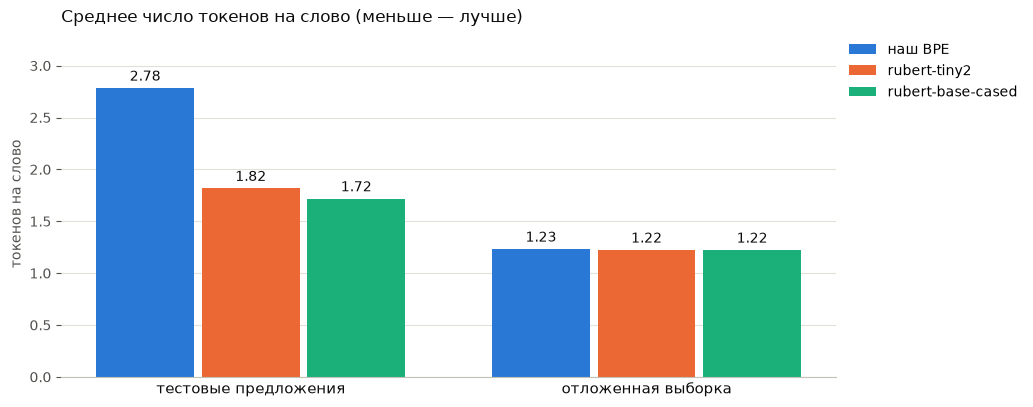

In [51]:
SERIES_COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']
INK, MUTED, GRID = '#0b0b0b', '#52514e', '#e1e0d9'


def plot_tokens_per_word(table: pd.DataFrame, title: str) -> None:
    """table: строки — токенизаторы, колонки — наборы текстов."""
    fig, ax = plt.subplots(figsize=(10, 4.5))
    bar_width = 0.8 / len(table.index)
    positions = range(len(table.columns))

    for index, (name, color) in enumerate(zip(table.index, SERIES_COLORS)):
        shift = (index - (len(table.index) - 1) / 2) * bar_width
        bars = ax.bar(
            [position + shift for position in positions], table.loc[name],
            width=bar_width - 0.02, color=color, label=name, zorder=2,
        )
        ax.bar_label(bars, fmt='%.2f', padding=3, color=INK, fontsize=10)

    ax.set_xticks(list(positions), table.columns, color=INK, fontsize=11)
    ax.set_ylabel('токенов на слово', color=MUTED)
    ax.set_title(title, color=INK, loc='left')
    ax.set_ylim(0, table.values.max() * 1.2)
    ax.grid(axis='y', color=GRID, linewidth=0.8, zorder=0)
    ax.tick_params(axis='y', colors=MUTED)
    ax.tick_params(axis='x', length=0)
    for side in ['top', 'right', 'left']:
        ax.spines[side].set_visible(False)
    ax.spines['bottom'].set_color('#c3c2b7')
    ax.legend(frameon=False, loc='upper left', bbox_to_anchor=(1.0, 1.0))
    plt.show()


fertility = pd.DataFrame({dataset: table['токенов на слово'] for dataset, table in metrics.items()})
plot_tokens_per_word(fertility, 'Среднее число токенов на слово (меньше — лучше)')

**Что показывают метрики:**

- **На современном тексте наш токенизатор режет слова в 1.5–1.6 раза мельче:** 2.78 токена на слово против 1.82 у `rubert-tiny2`
  и 1.72 у `rubert-base-cased`. Целиком остаются только 42% слов против 60%, а почти четверть кусочков — однобуквенные
  (24% против 12%): словарю не хватает кусочков современных слов, и он дробит их почти по буквам.
- **На тексте из той же книги — практически вровень:** 1.23 токена на слово против 1.22, целиком 83% слов — даже чуть больше,
  чем у RuBERT, — и меньше однобуквенных кусочков. Словарь на 16 тыс. токенов, обученный на одной книге, для этой книги
  не уступает словарям на 84 и 120 тыс., обученным на огромных корпусах.
- Тестовых слов всего 60, поэтому точные значения на них приблизительны, но разница в полтора раза видна и в таблицах раздела 3.3.

Вывод: качество токенизатора определяется тем, насколько обучающий корпус похож на тексты, к которым его применяют.
Большой разнообразный корпус и большой словарь нужны, чтобы токенизатор хорошо работал на любых текстах, а не только на «своих».

### 4.2 Неизвестные токены `[UNK]`

Считаем `[UNK]` во всём тексте (не только в словах, но и в знаках и эмодзи) и по позициям токенов в исходной строке (offsets)
находим, на каком фрагменте текста токенизатор «споткнулся». Добавляем и «голую» версию нашего токенизатора из раздела 2.5 —
без замены `ё` и без `initial_alphabet`.

In [52]:
unk_tokenizers = {
    'наш BPE': ru_tokenizer,
    'наш BPE («голый»)': ru_tokenizer_raw,
    'rubert-tiny2': reference_tokenizers['cointegrated/rubert-tiny2'],
    'rubert-base-cased': reference_tokenizers['DeepPavlov/rubert-base-cased'],
}


def tokens_with_offsets(tokenizer, text: str) -> list[tuple[str, tuple[int, int]]]:
    if isinstance(tokenizer, Tokenizer):
        encoding = tokenizer.encode(text, add_special_tokens=False)
        return list(zip(encoding.tokens, encoding.offsets))
    encoding = tokenizer(text, add_special_tokens=False, return_offsets_mapping=True)
    return list(zip(tokenizer.convert_ids_to_tokens(encoding['input_ids']), encoding['offset_mapping']))


def unk_report(texts: list[str]) -> pd.DataFrame:
    rows = {}
    for name, tokenizer in unk_tokenizers.items():
        fragments = Counter(
            text[start:end]
            for text in texts
            for token, (start, end) in tokens_with_offsets(tokenizer, text)
            if token == '[UNK]'
        )
        rows[name] = {
            '[UNK] всего': sum(fragments.values()),
            'на каких фрагментах': ', '.join(f'{fragment} ({count})' for fragment, count in fragments.most_common(12)) or '—',
        }
    return pd.DataFrame(rows).T


for dataset, texts in EVALUATION_TEXTS.items():
    display(Markdown(f'**{dataset}**'))
    display(unk_report(texts))

**тестовые предложения**

,[UNK] всего,на каких фрагментах
наш BPE,1,🍕 (1)
наш BPE («голый»),8,"ё (2), 🍕 (1), 5 (1), € (1), № (1), « (1), » (1)"
rubert-tiny2,2,"🍕 (1), — (1)"
rubert-base-cased,1,🍕 (1)


**отложенная выборка**

,[UNK] всего,на каких фрагментах
наш BPE,1,N (1)
наш BPE («голый»),6,"7 (2), 5 (2), N (1), 4 (1)"
rubert-tiny2,561,— (561)
rubert-base-cased,0,—


**Что показывают `[UNK]`:**

- **Основная версия нашего токенизатора** на тестовых предложениях спотыкается только на эмодзи 🍕, как и оба RuBERT.
  На отложенной выборке — один `[UNK]` на латинской `N`: этой буквы нет в обучающей части корпуса. Отложенная выборка поймала то,
  чего токенизатор не видел при обучении. Добавить букву в `initial_alphabet` помогло бы только частично: внутри слова
  понадобился бы ещё токен `##N`, которого `initial_alphabet` не создаёт.
- **«Голая» версия** без замены `ё` и без `initial_alphabet` спотыкается на `ё`, `€`, `№`, кавычках `«»` и цифрах: в книге
  этих символов нет или почти нет. Видно, что `[UNK]` появляется из-за неизвестного **символа**, а не неизвестного слова:
  незнакомые слова (`кринж`, `смартфон`) токенизатор собирает из кусочков, а незнакомый символ собрать не из чего.
- **`rubert-tiny2` даёт 561 `[UNK]` на отложенной выборке — на каждом длинном тире `—`.** В его словаре этого символа нет,
  а в очищенном корпусе тире оформлена вся прямая речь. В исходном тексте с `--` этой проблемы не было бы, но в обычных русских
  текстах тире встречается постоянно, так что это настоящая слабость модели.
- **`rubert-base-cased`** на книге не дал ни одного `[UNK]`.

Токенизаторы современных LLM (GPT, LLaMA 3, Qwen) используют byte-level BPE: любой символ раскладывается на байты,
поэтому `[UNK]` у них не бывает в принципе.

### 4.3 Эксперимент: размер словаря

Переобучаем токенизатор на том же корпусе со словарём в 2 раза меньше и в 2 раза больше основного.
Для 32 тыс. корпусу не хватит материала: обучение остановится на потолке около 24.6 тыс. токенов.

In [53]:
VOCAB_SIZES = [8_000, 16_000, 32_000]
EXPERIMENT_WORDS = [
    'Переосмысливаемый', 'недопонятого', 'железнодорожный', 'водохранилища', 'красивого', 'Пантелеймоновна', 'смартфон',
]


def bpe_tokenize_function(tokenizer: Tokenizer):
    return lambda text: tokenizer.encode(text, add_special_tokens=False).tokens


def experiment_table(tokenizers: dict[str, Tokenizer]) -> pd.DataFrame:
    rows = {}
    for label, tokenizer in tokenizers.items():
        row = {'размер словаря': tokenizer.get_vocab_size()}
        for dataset, texts in EVALUATION_TEXTS.items():
            row[f'токенов на слово: {dataset}'] = round(word_metrics(bpe_tokenize_function(tokenizer), texts)['токенов на слово'], 2)
        rows[label] = row
    return pd.DataFrame(rows).T.astype({'размер словаря': int})


def splits_table(tokenizers: dict[str, Tokenizer]) -> pd.DataFrame:
    return pd.DataFrame(
        {label: [' | '.join(bpe_tokenize_function(tokenizer)(word)) for word in EXPERIMENT_WORDS] for label, tokenizer in tokenizers.items()},
        index=EXPERIMENT_WORDS,
    )


vocab_size_tokenizers = {
    f'vocab_size = {size:,}': ru_tokenizer if size == VOCAB_SIZE else train_bpe_tokenizer(train_texts, vocab_size=size)
    for size in VOCAB_SIZES
}

display(experiment_table(vocab_size_tokenizers))
display(splits_table(vocab_size_tokenizers))

,размер словаря,токенов на слово: тестовые предложения,токенов на слово: отложенная выборка
"vocab_size = 8,000",8000,2.90,1.36
"vocab_size = 16,000",16000,2.78,1.23
"vocab_size = 32,000",24590,2.73,1.18


,"vocab_size = 8,000","vocab_size = 16,000","vocab_size = 32,000"
Переосмысливаемый,Пере | ##о | ##с | ##мысли | ##ваем | ##ый,Пере | ##о | ##с | ##мысли | ##ваем | ##ый,Пере | ##о | ##с | ##мысли | ##ваем | ##ый
недопонятого,недо | ##по | ##ня | ##того,недо | ##по | ##нятого,недо | ##по | ##нятого
железнодорожный,желез | ##но | ##доро | ##жный,железнодоро | ##жный,железнодоро | ##жный
водохранилища,во | ##дох | ##ран | ##или | ##ща,во | ##дох | ##ран | ##или | ##ща,во | ##дох | ##ран | ##или | ##ща
красивого,краси | ##вого,краси | ##вого,красивого
Пантелеймоновна,П | ##ан | ##телей | ##монов | ##на,П | ##ан | ##телей | ##монов | ##на,П | ##ан | ##телей | ##монов | ##на
смартфон,с | ##ма | ##рт | ##ф | ##он,с | ##ма | ##рт | ##ф | ##он,с | ##ма | ##рт | ##ф | ##он


**Что показал эксперимент с размером словаря:**

- **Уменьшение до 8 тыс.** ухудшило разбиение на тексте книги (1.36 токена на слово против 1.23) и чуть-чуть на тестовых
  предложениях (2.90 против 2.78): меньше слияний — слова режутся мельче (`недо | ##по | ##ня | ##того`).
- **Увеличение до потолка (~24.6 тыс.)** помогло на тексте книги (1.18), но почти не изменило результат на тестовых
  предложениях (2.73). Новые токены — это целые частые слова книги (`красивого` стал одним токеном), а `смартфон`
  и `водохранилища` режутся одинаково при любом размере: нужных кусочков в корпусе просто нет.

Размер словаря определяет, сколько частых слов корпуса токенизатор запомнит целиком. Дать кусочки слов, которых нет в корпусе,
он не может.

### 4.4 Эксперимент: объём корпуса

Русская сторона есть во всех шести языковых парах `opus_books` с русским языком. Объединяем их, чистим той же функцией,
убираем повторы и предложения из отложенной выборки (иначе токенизатор увидел бы проверочные тексты при обучении).
Большинство пар — переводы той же «Анны Карениной», но есть и другие книги, поэтому корпус вырастет почти вдвое.

In [54]:
RU_CONFIGS = ['de-ru', 'en-ru', 'es-ru', 'fr-ru', 'hu-ru', 'it-ru']

all_ru_texts = []
print('Предложений в языковых парах:')
for config in RU_CONFIGS:
    pairs = load_dataset(DATASET_NAME, config, split='train')['translation']
    all_ru_texts += [pair['ru'] for pair in pairs]
    print(f'  {config}: {len(pairs):,}')

holdout_set = set(holdout_texts)
big_corpus = sorted({text for text in map(clean_text, all_ru_texts) if not is_garbage(text)} - holdout_set)

print()
print(f'Объединённый корпус — предложений: {len(big_corpus):,}, символов: {sum(map(len, big_corpus)):,}')
print(f'Основной корпус     — предложений: {len(train_texts):,}, символов: {sum(map(len, train_texts)):,}')

Предложений в языковых парах:


  de-ru: 17,373


  en-ru: 17,496


  es-ru: 16,793


  fr-ru: 8,197


  hu-ru: 26,127


  it-ru: 17,906



Объединённый корпус — предложений: 29,302, символов: 2,945,712
Основной корпус     — предложений: 16,395, символов: 1,598,915


In [55]:
corpus_size_tokenizers = {
    'одна книга, 16 000': ru_tokenizer,
    'одна книга, потолок': vocab_size_tokenizers['vocab_size = 32,000'],
    'все пары, 16 000': train_bpe_tokenizer(big_corpus),
    'все пары, потолок': train_bpe_tokenizer(big_corpus, vocab_size=50_000),
}

display(experiment_table(corpus_size_tokenizers))
display(splits_table(corpus_size_tokenizers))

,размер словаря,токенов на слово: тестовые предложения,токенов на слово: отложенная выборка
"одна книга, 16 000",16000,2.78,1.23
"одна книга, потолок",24590,2.73,1.18
"все пары, 16 000",16000,2.75,1.24
"все пары, потолок",42630,2.47,1.12


,"одна книга, 16 000","одна книга, потолок","все пары, 16 000","все пары, потолок"
Переосмысливаемый,Пере | ##о | ##с | ##мысли | ##ваем | ##ый,Пере | ##о | ##с | ##мысли | ##ваем | ##ый,Пере | ##о | ##с | ##мысли | ##ваемый,Перео | ##с | ##мысли | ##ваемый
недопонятого,недо | ##по | ##нятого,недо | ##по | ##нятого,недо | ##по | ##ня | ##того,недо | ##по | ##нятого
железнодорожный,железнодоро | ##жный,железнодоро | ##жный,железнодоро | ##жный,железнодорожный
водохранилища,во | ##дох | ##ран | ##или | ##ща,во | ##дох | ##ран | ##или | ##ща,во | ##дох | ##ран | ##или | ##ща,во | ##дох | ##ран | ##или | ##ща
красивого,краси | ##вого,красивого,краси | ##вого,красивого
Пантелеймоновна,П | ##ан | ##телей | ##монов | ##на,П | ##ан | ##телей | ##монов | ##на,П | ##ан | ##телей | ##монов | ##на,П | ##ан | ##телей | ##монов | ##на
смартфон,с | ##ма | ##рт | ##ф | ##он,с | ##ма | ##рт | ##ф | ##он,с | ##ма | ##рт | ##фон,сма | ##рт | ##фон


**Что показал эксперимент с объёмом корпуса:**

- **С тем же словарём на 16 тыс. корпус в 1.8 раза больше почти ничего не дал** (2.75 против 2.78 и 1.24 против 1.23).
  Добавились переводы той же «Анны Карениной» и другая классическая проза: новых слов в них немного, а словарь того же размера
  заполняется примерно теми же кусочками.
- **Зато вырос потолок словаря** — с 24.6 до 42.6 тыс. токенов. С полным словарём результат лучший из всех: 2.47 токена на слово
  на тестовых предложениях и 1.12 на отложенной выборке, а `железнодорожный` и `красивого` стали целыми токенами.
- `водохранилища` и `Пантелеймоновна` режутся одинаково во всех вариантах: таких слов нет ни в одной из книг.
  Важен не только объём корпуса, но и его разнообразие: токенизатор не выучит кусочки слов, которых он не видел.

### 4.5 Токенизаторы LLM и контекстное окно

Сравним с токенизаторами двух генерирующих моделей. Оба — **byte-level BPE**: начальный алфавит у них — 256 байтов, а не буквы,
поэтому `[UNK]` не бывает, но русская буква занимает в UTF-8 2 байта и может разрезаться пополам.
- [`openai-community/gpt2`](https://huggingface.co/openai-community/gpt2) — GPT-2, словарь 50 тыс., обучен в основном на английском;
- [`Qwen/Qwen2.5-0.5B`](https://huggingface.co/Qwen/Qwen2.5-0.5B) — современная многоязычная модель, словарь 151 тыс.

Byte-level токенизаторы хранят пробел внутри токена (`␣слово` и `слово` — разные токены), поэтому слово, поданное отдельно,
режется у них иначе, чем внутри фразы. Чтобы сравнение было честным, здесь считаем токены по целым текстам и делим на число слов
(знаки препинания тоже попадают в счёт, поэтому числа чуть больше, чем в разделе 4.1).

Во время подсчёта `transformers` выведет красное предупреждение `Token indices sequence length is longer than the specified maximum
sequence length for this model (1144 > 1024)`. Это не ошибка: саму модель GPT-2 мы не запускаем, а только режем текст на токены.
Но предупреждение показательно: одно предложение из отложенной выборки превратилось у GPT-2 в 1 144 токена, а контекстное окно
GPT-2 — всего 1 024 токена.

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1144 > 1024). Running this sequence through the model will result in indexing errors


,тестовые предложения,отложенная выборка
наш BPE,3.05,1.53
rubert-tiny2,2.07,1.52
rubert-base-cased,1.97,1.52
gpt2,9.92,6.75
Qwen2.5-0.5B,3.72,2.31


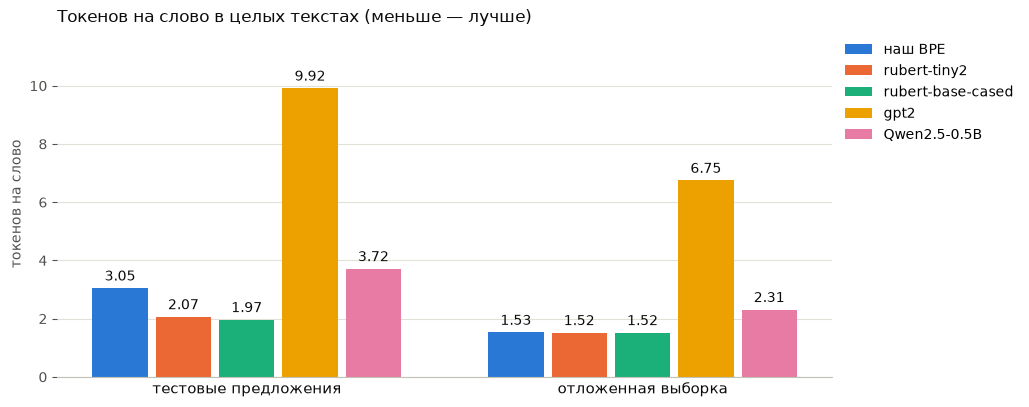

In [56]:
LLM_MODELS = ['openai-community/gpt2', 'Qwen/Qwen2.5-0.5B']

llm_tokenizers = {name.split('/')[1]: AutoTokenizer.from_pretrained(name) for name in LLM_MODELS}
text_tokenize_functions = tokenize_functions | {name: tokenizer.tokenize for name, tokenizer in llm_tokenizers.items()}


def tokens_per_word_in_texts(tokenize, texts: list[str]) -> float:
    words = sum(len(WORD_PATTERN.findall(text)) for text in texts)
    tokens = sum(len(tokenize(text)) for text in texts)
    return tokens / words


llm_fertility = pd.DataFrame({
    dataset: {name: tokens_per_word_in_texts(tokenize, texts) for name, tokenize in text_tokenize_functions.items()}
    for dataset, texts in EVALUATION_TEXTS.items()
})
display(llm_fertility.round(2))
plot_tokens_per_word(llm_fertility, 'Токенов на слово в целых текстах (меньше — лучше)')

Как byte-level токенизатор режет русское слово. Каждый токен переводим обратно в текст: символ `�` означает,
что в токене оказалась половина буквы (один байт из двух).

In [57]:
word = 'Переосмысливаемый'
for name, tokenizer in llm_tokenizers.items():
    pieces = [tokenizer.convert_tokens_to_string([token]) for token in tokenizer.tokenize(word)]
    print(f'{name:13} {len(pieces):2} токенов: {pieces}')

print()
same_meaning = {
    'английский': 'The agricultural cooperative repaired the railway crossing near the reservoir.',
    'русский': TEST_SENTENCES[2][1],
}
pd.DataFrame({
    language: {name: len(tokenize(text)) for name, tokenize in text_tokenize_functions.items()}
    for language, text in same_meaning.items()
})

gpt2          19 токенов: ['�', '�', 'е', 'р', 'е', 'о', 'с', 'м', 'ы', 'с', 'л', 'и', 'в', 'а', 'е', 'м', 'ы', '�', '�']
Qwen2.5-0.5B   8 токенов: ['Пер', 'е', 'ос', 'мы', 'сли', 'в', 'аем', 'ый']



,английский,русский
наш BPE,48,27
rubert-tiny2,13,11
rubert-base-cased,25,9
gpt2,11,96
Qwen2.5-0.5B,11,33


**Что показало сравнение с LLM:**

- **GPT-2 тратит на русское слово около 10 токенов** на современном тексте и почти 7 на тексте книги — в 3–4 раза больше,
  чем наш маленький токенизатор. Его словарь построен на английских текстах, русских кусочков в нём почти нет, и слова
  распадаются на отдельные буквы и даже половинки букв (`�`). Одно и то же предложение занимает 11 токенов на английском
  и 96 на русском: в контекстное окно влезает в 9 раз меньше русского текста, а запрос через API стоит в 9 раз дороже.
- **Одно предложение Толстого не влезает в GPT-2.** Самое длинное предложение отложенной выборки (150 слов, 1 093 символа)
  занимает у GPT-2 1 144 токена — больше всего его контекстного окна в 1 024 токена. У RuBERT это же предложение — около 215 токенов,
  у нашего токенизатора — около 270, у Qwen2.5 — 362.
- **Qwen2.5 со многоязычным словарём заметно лучше** (3.72 и 2.31 токена на слово), но на русском всё равно уступает
  специализированным токенизаторам: русскому языку достаётся только часть из 151 тыс. токенов. То же предложение — 33 токена
  против 11 на английском.
- **Наш токенизатор на тексте книги — на уровне RuBERT** (1.53 против 1.52) и вдвое экономнее GPT-2 даже на чужом для себя
  современном тексте.

Именно поэтому для русскоязычных задач важен токенизатор, обученный на русских текстах: от него зависят длина последовательностей,
объём текста в контекстном окне, скорость генерации и стоимость.

## 5. Отчёт и выводы

### 5.1 Что настроено

| Этап | Решение | Почему |
|---|---|---|
| Корпус | русская сторона `Helsinki-NLP/opus_books`, пара `en-ru`: 17 496 предложений, 1.7 млн символов | корпус из задания; по сути это одна книга — «Анна Каренина» |
| Очистка | NFC, `--` → `—`, многоточия → `...`, удалены 239 заголовков глав (`XIV`) и пустые строки | артефакты форматирования засоряли бы словарь; пунктуацию, регистр и формы слов не трогаем — токенизатор должен работать с настоящим текстом |
| Отложенная выборка | 5% предложений (862) не участвуют в обучении | честная проверка на незнакомом тексте того же стиля |
| Подача данных | генератор батчей по 1 000 предложений → `train_from_iterator` | корпус не обязан целиком лежать в памяти |
| Алгоритм | **BPE**, продолжения слов помечены `##` | основа токенизаторов GPT, LLaMA, Qwen; `##` — для сравнения с RuBERT в одном формате |
| Normalizer | NFC + `ё` → `е` | в корпусе нет буквы `ё`, без замены любое слово с ней давало бы `[UNK]` |
| Pre-tokenizer | разбиение по пробелам + изоляция каждого знака препинания + цифры по одной | знаки препинания не склеиваются со словами |
| Trainer | `vocab_size=16 000`, `min_frequency=2`, спецтокены `[PAD] [UNK] [CLS] [SEP] [MASK]`, `initial_alphabet` с `— « » … № % €` и цифрами | словарь с запасом ниже потолка корпуса (~24.6 тыс.); редкие символы не дают `[UNK]` |
| Post-processor и decoder | `[CLS] … [SEP]`, сборка `##`-кусочков обратно в слова | формат как у BERT |
| Результат | `tokenizer/ru_bpe.json` (~1.3 МБ), обучение меньше секунды | словарь и правила слияний в одном файле |

### 5.2 Пословное сравнение

Кусочки разделены пробелами; полные таблицы для всех тестовых предложений — в разделе 3.3.

| Исходное слово | Наш BPE (16 тыс.) | rubert-tiny2 (84 тыс.) | rubert-base-cased (120 тыс.) |
|---|---|---|---|
| Переосмысливаемый | `Пере ##о ##с ##мысли ##ваем ##ый` | `Пер ##ео ##см ##ыс ##лива ##емый` | `Пере ##осм ##ысл ##иваемый` |
| недопонятого | `недо ##по ##нятого` | `недо ##пон ##ятого` | `недоп ##он ##ято ##го` |
| передумать | `пере ##думать` | `передума ##ть` | `передум ##ать` |
| Сельскохозяйственный | `С ##ель ##ско ##хо ##зя ##й ##ственный` | `Сель ##скохозяй ##ственный` | `Сельскохозяйственный` |
| железнодорожный | `железнодоро ##жный` | `железнодорожный` | `железнодорожный` |
| загуглил | `за ##гу ##г ##лил` | `загу ##гли ##л` | `заг ##угли ##л` |
| кринж | `кри ##н ##ж` | `кри ##н ##ж` | `кри ##н ##ж` |
| смартфон | `с ##ма ##рт ##ф ##он` | `смартфон` | `смартфон` |
| Пантелеймоновна | `П ##ан ##телей ##монов ##на` | `Панте ##лей ##монов ##на` | `Пантелей ##монов ##на` |
| столами | `стола ##ми` | `стола ##ми` | `стола ##ми` |
| Аркадьич | `Аркадьич` | `Арка ##дь ##ич` | `Аркад ##ьи ##ч` |
| улыбнулся | `улыбнулся` | `улыбнулся` | `улыб ##нулся` |

### 5.3 Метрики

| | Наш BPE | rubert-tiny2 | rubert-base-cased |
|---|---|---|---|
| токенов на слово, тестовые предложения | 2.78 | 1.82 | 1.72 |
| токенов на слово, отложенная выборка | 1.23 | 1.22 | 1.22 |
| слов целиком, тестовые предложения | 42% | 60% | 60% |
| слов целиком, отложенная выборка | 83% | 83% | 82% |
| `[UNK]`, тестовые предложения | 1 (эмодзи) | 2 (эмодзи, `—`) | 1 (эмодзи) |
| `[UNK]`, отложенная выборка | 1 (латинская `N`) | 561 (все `—`) | 0 |

Для сравнения, по целым текстам у GPT-2 9.92 и 6.75 токена на слово, у Qwen2.5 — 3.72 и 2.31 (раздел 4.5).

### 5.4 Самые удачные и самые неудачные разбиения

**Удачные** — границы токенов совпали с морфемами:
- `под | ##ход`, `пере | ##думать`, `про | ##читал` — приставка отделена от основы;
- `пере | ##дум | ##анный`, `недо | ##чит | ##анный` — приставка, корень и суффикс с окончанием;
- `чита | ##ет`, `под | ##коми | ##сси | ##ями` — выделены окончания;
- `Аркадьич`, `улыбнулся`, `Александровича` — частые слова книги целиком, лучше, чем у RuBERT.

**Неудачные** — бессмысленные наборы букв:
- `с | ##ма | ##рт | ##ф | ##он`, `во | ##дох | ##ран | ##или | ##ща`, `С | ##ель | ##ско | ##хо | ##зя | ##й | ##ственный` —
  слов нет в корпусе, они собираются почти по буквам;
- `зако | ##но | ##про | ##ек | ##ты` — граница проходит внутри корня `закон`;
- `переп | ##ис | ##ать`, `пер | ##ер | ##ас | ##с | ##матри | ##вались` — приставки разорваны;
- `стола | ##ми`, `краси | ##вая` — граница сдвинута относительно окончания.

### 5.5 Как токенизатор справился с русской морфологией

- **Приставки выучены.** Все 12 проверенных приставок (`пере`, `под`, `недо`, `за`, `при`, `про`, `раз`, `рас`, `без`, `от`, `вы`, `пред`)
  есть в словаре, и токенизатор часто отделяет их от основы — иногда точнее, чем RuBERT (`пере | ##думать` против `передума | ##ть`).
- **Окончания — частично.** Есть `##ая`, `##ый`, `##ий`, `##ые`, `##ами`, `##ями`, `##ать`, `##ает`, но нет `##ого`, `##ому`, `##ость`:
  BPE склеивает пары жадно, и гласная окончания «прилипает» к предыдущей согласной в самых первых слияниях. Вместо `##ого`
  в словаре десятки токенов «кусок основы + ого»: `##ного`, `##кого`, `##ского`.
- **Частые слова запоминаются целиком** (`нового`, `которого`, почти все формы слова `стол`), поэтому морфологическое разбиение
  видно только на более редких словах.
- **Морфологию токенизатор выучил интуитивно**, как побочный эффект статистики: самые частые кусочки русских слов — это и есть
  приставки и окончания. Там, где частотность расходится с морфологией, граница проходит «не по морфемам» — причём `стола | ##ми`
  так же режут и оба RuBERT: WordPiece тоже статистический алгоритм.

### 5.6 Общий вывод

**Почему готовые решения работают точнее.** RuBERT обучали на корпусах в тысячи раз больше и разнообразнее нашего (Википедия,
новости, а не одна книга XIX века), а их словари в 5–7 раз больше. Поэтому в них уже есть `железнодорожный`, `смартфон`,
`водохранилища`, и на современном тексте они режут слова в 1.5–1.6 раза крупнее нашего токенизатора (1.72–1.82 токена на слово
против 2.78). При этом на тексте той же книги наш токенизатор с 16 тыс. токенов работает **на их уровне** (1.23 против 1.22):
качество токенизатора определяется прежде всего тем, насколько обучающий корпус похож на тексты, к которым его применяют.

**Как влияет объём корпуса.** Корпус задаёт, какие кусочки слов токенизатор вообще может выучить: слов, которых нет в корпусе,
он не соберёт осмысленно при любом размере словаря. Важен не только объём, но и разнообразие: корпус в 1.8 раза больше,
но из похожих книг, при том же словаре почти ничего не изменил (2.75 против 2.78). Больший корпус поднимает потолок словаря
(с 24.6 до 42.6 тыс.), и с полным словарём разбиение стало лучшим (2.47 и 1.12).

**Как влияет размер словаря.** Больше словарь — больше частых слов запоминается целиком и последовательности короче:
8 тыс. → 16 тыс. → 24.6 тыс. дают 1.36 → 1.23 → 1.18 токена на слово на тексте книги. Но словарь не может быть больше, чем позволяет
корпус: при `min_frequency=2` наш корпус упирается в ~24.6 тыс. токенов. А на современных словах рост словаря почти не помогает
(2.90 → 2.73): нужных кусочков в книге просто нет. Обратная сторона большого словаря — больше параметров в эмбеддинг-слое модели.

**Почему это важно для LLM.** От токенизатора зависит, сколько токенов займёт текст, а значит — сколько текста влезет в контекстное
окно, как быстро модель его сгенерирует и сколько будет стоить запрос через API. Англоязычный GPT-2 тратит на русское предложение
в 9 раз больше токенов, чем на английское; многоязычный Qwen2.5 — в 3 раза. Токенизатор, обученный на большом и разнообразном
русском корпусе, делает модель для русского языка заметно эффективнее.